# 🍽️ Analyse et recommandation de produits à partir des avis clients
### Projet — *Advanced Learning for Text and Graph Data* (Unit: IL)

**Dataset :** Amazon Fine Food Reviews (SNAP / Kaggle) — 568 454 avis, 256 059 utilisateurs, 74 258 produits (1999 → 2012).

**Objectif :** combiner **NLP** et **graphes** pour
1. détecter le **sentiment** d'un avis ;
2. **découvrir des thèmes** (topic modelling) et **des communautés** d'utilisateurs ;
3. **prédire des notes** avec des **GNN / Graph Transformer Network (GTN)** ;
4. construire un **système de recommandation** ;
5. répondre à des questions via un **Graph-RAG** (mini Q&A sur le graphe).

---
### 🗺️ Fil conducteur du notebook (et lien avec le cours)

| Partie | Contenu | Chapitre du cours |
|---|---|---|
| 0 | Installation, configuration | — |
| 1 | Chargement, exploration (EDA), nettoyage | Ch.1 (typologie des données) |
| 2 | Pré-traitement du texte | Ch.1 (tokenisation, stop-words, lemmatisation) |
| 3 | Analyse de sentiment : TF-IDF → embeddings → BERT | Ch.1 (vectorisation) + Ch.2 (Transformers/BERT) |
| 4 | Topic modelling (LDA) et clustering d'embeddings | Ch.1 (tâches avancées NLU) |
| 5 | Construction du graphe utilisateurs–produits, communautés | Ch.1 (graphes en NLP) |
| 6 | Prédiction de notes : GNN vs **GTN** (attention) | Ch.2 (GTN) |
| 7 | Système de recommandation | Ch.1–2 |
| 8 | **Graph-RAG** : questions/réponses | Ch.4 (RAG, Graph-RAG) |
| 9 | Sauvegarde des livrables | — |
| **10** | **Déploiement Streamlit** (application web, test, lancement public) | Mise en production |
| 11 | Conclusion, limites, perspectives | — |

> ⚙️ **Environnement conseillé :** Colab avec **GPU** (*Exécution → Modifier le type d'exécution → GPU T4*). Temps total ≈ 25–35 min.
> Les cellules lourdes (BERT, GNN) sont contrôlées par des **interrupteurs** (`RUN_BERT`, `RUN_GNN`, `RUN_LLM`) dans la cellule de configuration.

## 0. Installation et configuration

### Pourquoi cette cellule ?
Colab possède déjà `pandas`, `scikit-learn`, `networkx`, `matplotlib`, `torch`, `transformers`. Il nous manque :
- **`sentence-transformers`** : pour obtenir des *embeddings contextuels* de phrases (modèle `all-MiniLM-L6-v2`, basé sur un Transformer encodeur type BERT) ;
- **`torch_geometric`** (PyG) : bibliothèque de GNN. Elle fournit `SAGEConv`, `GATConv` et **`TransformerConv`**, qui est la couche *Graph Transformer* (attention multi-têtes sur les voisins du graphe).

Le flag `-q` rend l'installation silencieuse.

In [1]:
!pip -q install sentence-transformers torch_geometric

### Imports, graines aléatoires et paramètres globaux

- **Graine (`SEED`)** : fixe l'aléatoire pour que les résultats soient **reproductibles**.
- **`K_CORE`** : on ne garde dans le graphe que les utilisateurs **et** produits ayant au moins `K_CORE` avis (explication détaillée en section 1.5).
- **`TEST_SIZE`** : part des avis mise de côté pour l'évaluation finale (20 %).
- **Interrupteurs** : `RUN_BERT` (fine-tuning DistilBERT, GPU conseillé), `RUN_GNN` (entraînement GNN/GTN), `RUN_LLM` (génération de réponses avec Flan-T5 dans le Graph-RAG).
- **`device`** : `cuda` si un GPU est disponible, sinon `cpu`.

In [2]:
import os, sys, re, html, time, json, warnings, collections, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy.sparse as sp
warnings.filterwarnings('ignore')

SEED       = 42      # reproductibilité
K_CORE     = 3       # un nœud (user/produit) doit avoir >= K_CORE avis pour rester dans le graphe
TEST_SIZE  = 0.20    # part des avis réservée au test
RUN_BERT   = True    # fine-tuning de DistilBERT (nécessite un GPU pour rester rapide)
RUN_GNN    = True    # entraînement des GNN / GTN
RUN_LLM    = False   # génération de réponses avec Flan-T5 dans le Graph-RAG (optionnel)

np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    HAS_TORCH = True
except ImportError:
    device, HAS_TORCH = 'cpu', False
print('Device :', device, '| torch disponible :', HAS_TORCH)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('outputs', exist_ok=True)   # dossier des livrables

Device : cuda | torch disponible : True


#### 🔎 Lecture du résultat
La cellule affiche le **device** utilisé. `cuda` = GPU détecté (indispensable pour accélérer MiniLM, DistilBERT et les GNN). Si vous lisez `cpu`, activez un GPU (*Exécution → Modifier le type d'exécution*) ou laissez `RUN_BERT=False` : le reste du notebook fonctionne sur CPU, simplement plus lentement pour l'encodage des embeddings.

## 1. Chargement et exploration des données (EDA)

### 1.1 Chargement du fichier `Reviews.csv`
Le fichier `archive.zip` contient `Reviews.csv` (300 Mo), `database.sqlite` (même données au format SQLite) et `hashes.txt` (empreintes MD5 de vérification). **Nous n'utilisons que `Reviews.csv`.**

Deux options pour fournir le fichier à Colab :
- **Option A (recommandée)** : déposer `archive.zip` dans votre Google Drive (`Mon Drive/archive.zip`) ; la cellule le monte et extrait uniquement `Reviews.csv`.
- **Option B** : envoyer le zip manuellement via le panneau *Fichiers* de Colab (glisser-déposer dans `/content`), puis relancer la cellule.

Colonnes du dataset : `Id`, `ProductId`, `UserId`, `ProfileName`, `HelpfulnessNumerator/Denominator` (votes « avis utile »), `Score` (note 1–5), `Time` (timestamp Unix), `Summary` (titre), `Text` (avis).

In [3]:
import zipfile
IN_COLAB = 'google.colab' in sys.modules
CSV_PATH = '/content/data/Reviews.csv'
if not os.path.exists(CSV_PATH):
    os.makedirs('/content/data', exist_ok=True)
    if IN_COLAB:
        zip_candidates = ['/content/archive.zip', '/content/drive/MyDrive/archive.zip']
        if not os.path.exists(zip_candidates[0]):
            from google.colab import drive
            drive.mount('/content/drive')
        zip_path = next(p for p in zip_candidates if os.path.exists(p))
        with zipfile.ZipFile(zip_path) as z:
            z.extract('Reviews.csv', '/content/data')      # on n'extrait que le CSV
    else:
        raise FileNotFoundError('Placez Reviews.csv dans ' + CSV_PATH)

df_raw = pd.read_csv(CSV_PATH)
print('Dimensions brutes :', df_raw.shape)
df_raw.head(3)

Dimensions brutes : (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...


#### 🔎 Lecture du résultat
Le fichier contient **568 454 lignes × 10 colonnes** : une ligne = un avis. On voit tout de suite la nature des variables : deux **identifiants** (`UserId`, `ProductId`) qui feront les **nœuds du graphe**, une **note** (`Score`) qui fera le **poids des arêtes** et la **cible du sentiment**, et deux champs de **texte** (`Summary`, `Text`) qui nourriront le NLP. Les avis ont aussi un horodatage `Time` (secondes Unix).

### 1.2 Structure, types et valeurs manquantes
On vérifie les types (`info`), les valeurs manquantes et les statistiques de base. C'est la première étape de tout projet data : **savoir ce que l'on manipule** avant de modéliser.

In [4]:
df_raw.info()
print('\nValeurs manquantes par colonne :')
print(df_raw.isna().sum()[lambda s: s > 0])
print('\nPériode couverte :', pd.to_datetime(df_raw.Time, unit='s').min().date(), '→', pd.to_datetime(df_raw.Time, unit='s').max().date())
print('Utilisateurs uniques :', df_raw.UserId.nunique(), '| Produits uniques :', df_raw.ProductId.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB

Valeurs manquantes par colonne :
ProfileName    26
Summary        27
dtype: int64

Période couverte : 1999-10-08 → 2012-10-26
Utilisateurs uniques : 256059 | Produits uniques : 74258


#### 🔎 Lecture du résultat
- **Données quasi complètes** : seulement 26 `ProfileName` et 27 `Summary` manquants, **aucun `Text` manquant** → pas d'imputation nécessaire.
- **Période** : 8 octobre 1999 → 26 octobre 2012, soit 13 ans d'avis.
- **256 059 utilisateurs** et **74 258 produits** pour 568 454 avis → en moyenne **2,2 avis par utilisateur** et **7,7 avis par produit**. Ces moyennes basses annoncent un graphe **très creux** (confirmé en 1.4).

### 1.3 Distribution des notes
Le **déséquilibre des classes** conditionne toute la suite : un modèle qui prédit toujours « 5 étoiles » aurait déjà ~64 % d'accuracy. C'est pourquoi nous utiliserons le **F1 macro** (moyenne des F1 par classe) et pas seulement l'accuracy.

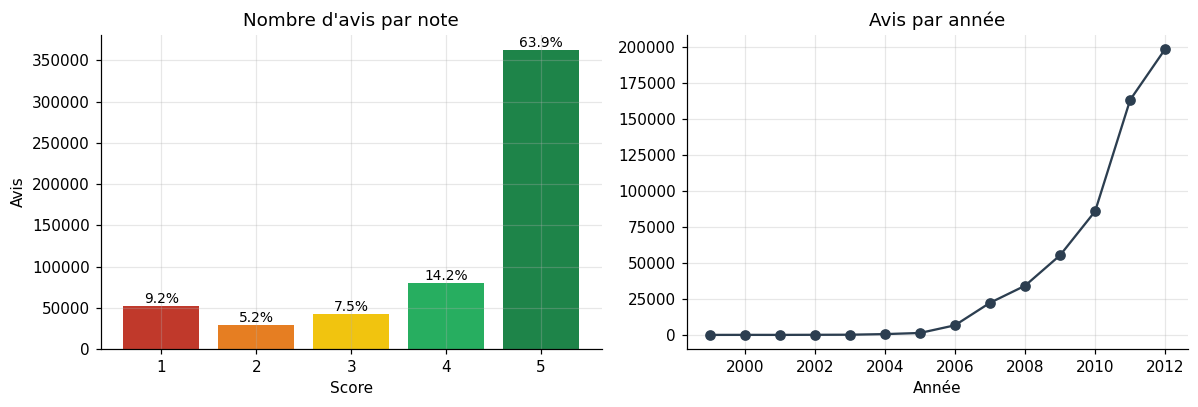

Score
1     9.19
2     5.24
3     7.50
4    14.19
5    63.88
Name: proportion, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
vc = df_raw.Score.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=['#c0392b','#e67e22','#f1c40f','#27ae60','#1e8449'])
ax[0].set_title('Nombre d\'avis par note'); ax[0].set_xlabel('Score'); ax[0].set_ylabel('Avis')
for x, v in vc.items(): ax[0].text(x, v, f'{v/len(df_raw):.1%}', ha='center', va='bottom', fontsize=9)
yr = pd.to_datetime(df_raw.Time, unit='s').dt.year.value_counts().sort_index()
ax[1].plot(yr.index, yr.values, marker='o', color='#2c3e50'); ax[1].set_title('Avis par année'); ax[1].set_xlabel('Année')
plt.tight_layout(); plt.show()
print((df_raw.Score.value_counts(normalize=True).sort_index()*100).round(2))

#### 🔎 Lecture du résultat
Distribution en **« J »** typique des avis en ligne : **63,9 % de 5 étoiles**, 14,2 % de 4, 7,5 % de 3, 5,2 % de 2 et 9,2 % de 1. Les extrêmes (1 et 5) dominent les notes intermédiaires : on écrit un avis quand on est très content ou très déçu.

**Conséquences pour la modélisation :**
- **78 % des avis sont positifs (4–5)** : un classifieur « toujours positif » aurait déjà ~78 % d'accuracy → l'accuracy seule est trompeuse, d'où l'usage du **F1 macro**.
- Les notes basses sont minoritaires, donc plus difficiles à apprendre → pondération des classes (`class_weight='balanced'`).
- L'activité croît de façon quasi exponentielle depuis 2006 (≈ 22 000 avis en 2007, ≈ 163 000 en 2011, ≈ 199 000 en 2012 qui est une année partielle) : le corpus est dominé par les années récentes.

### 1.4 Longueur des avis et « longue traîne » d'activité
- La **longueur des avis** (en mots) indique la quantité de texte exploitable par les modèles (et la limite de tokens à choisir pour BERT).
- La **longue traîne** (peu d'utilisateurs/produits très actifs, énormément de peu actifs) est typique des systèmes de recommandation : elle explique le problème de **sparsité** et le **cold-start**.

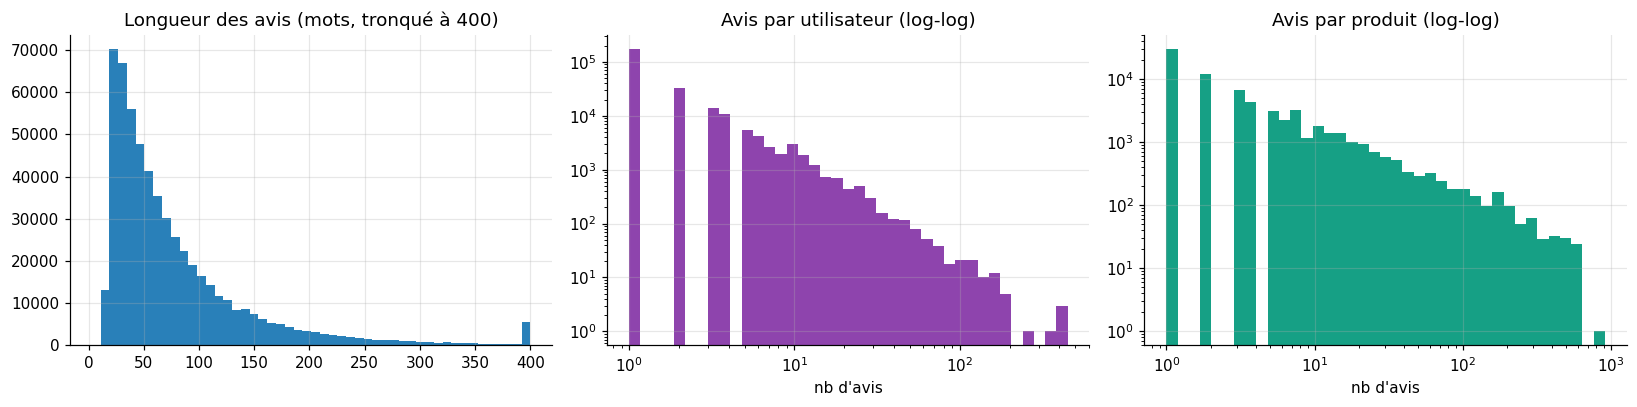

Longueur médiane : 56 mots | 95e percentile : 218
Avis par utilisateur : médiane = 1 | max = 448 | utilisateurs avec 1 seul avis = 68.5%
Avis par produit     : médiane = 2 | max = 913 | produits avec <5 avis = 72.5%


In [6]:
df_raw['n_words'] = df_raw.Text.str.split().str.len()
u_act = df_raw.groupby('UserId').size(); p_act = df_raw.groupby('ProductId').size()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df_raw.n_words.clip(upper=400), bins=50, color='#2980b9'); ax[0].set_title('Longueur des avis (mots, tronqué à 400)')
ax[1].hist(u_act, bins=np.logspace(0, np.log10(u_act.max()), 40), color='#8e44ad'); ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_title('Avis par utilisateur (log-log)'); ax[1].set_xlabel('nb d\'avis')
ax[2].hist(p_act, bins=np.logspace(0, np.log10(p_act.max()), 40), color='#16a085'); ax[2].set_xscale('log'); ax[2].set_yscale('log')
ax[2].set_title('Avis par produit (log-log)'); ax[2].set_xlabel('nb d\'avis')
plt.tight_layout(); plt.show()
print('Longueur médiane :', int(df_raw.n_words.median()), 'mots | 95e percentile :', int(df_raw.n_words.quantile(.95)))
print('Avis par utilisateur : médiane =', int(u_act.median()), '| max =', u_act.max(), '| utilisateurs avec 1 seul avis =', f'{(u_act==1).mean():.1%}')
print('Avis par produit     : médiane =', int(p_act.median()), '| max =', p_act.max(), '| produits avec <5 avis =', f'{(p_act<5).mean():.1%}')

#### 🔎 Lecture du résultat
- **Texte** : médiane de **56 mots**, 95ᵉ percentile à **218 mots**. Avec `max_seq_length = 128` tokens (≈ 95 mots), les modèles Transformers lisent **intégralement environ 3 avis sur 4** (le 75ᵉ percentile est à 98 mots) ; seuls les longs avis sont tronqués, et le début d'un avis (titre + première phrases) porte généralement l'essentiel du sentiment.
- **Longue traîne massive** : **68,5 % des utilisateurs n'ont écrit qu'un seul avis** (médiane = 1, maximum = 448) et **72,5 % des produits ont moins de 5 avis** (médiane = 2, maximum = 913). Les graphiques log-log sont presque des droites : signature d'une loi de puissance.
- **Implication** : sur ces nœuds peu connectés, on ne peut ni apprendre de préférences collaboratives, ni évaluer une recommandation. D'où le filtrage *k-core* (section 2.1).

### 1.5 Nettoyage des données

Quatre problèmes classiques de ce dataset (documentés sur Kaggle) :
1. **Avis dupliqués** : le même avis (même utilisateur, même date, même texte) est recopié pour plusieurs variantes d'un produit (ex. goûts différents) → il fausserait les statistiques et créerait des **fuites** entre train et test (le même texte des deux côtés). On garde une seule copie.
2. **Votes incohérents** : `HelpfulnessNumerator > HelpfulnessDenominator` est impossible (plus de « utile » que de votes).
3. **Textes manquants** : à supprimer (rien à analyser).
4. **Plusieurs avis du même utilisateur sur le même produit** : dans un graphe *simple* utilisateur–produit, il n'y a qu'**une arête** par paire ; on garde le plus récent.

On affiche l'effet de chaque étape pour tracer ce qui est supprimé.

In [7]:
steps = [('Brut', len(df_raw))]
df = df_raw.dropna(subset=['Text']);                                              steps.append(('Texte non vide', len(df)))
df = df.drop_duplicates(subset=['UserId', 'Time', 'Text']);                       steps.append(('Sans avis dupliqués', len(df)))
df = df[df.HelpfulnessNumerator <= df.HelpfulnessDenominator];                    steps.append(('Votes cohérents', len(df)))
df = df.drop_duplicates(subset=['UserId', 'ProductId'], keep='last').reset_index(drop=True); steps.append(('1 avis / (user, produit)', len(df)))
print(pd.DataFrame(steps, columns=['Étape', 'Nb d\'avis']).assign(Perdus=lambda d: d['Nb d\'avis'].diff().fillna(0).astype(int)).to_string(index=False))
print(f'\nAvis conservés : {len(df):,} ({len(df)/len(df_raw):.1%} du brut)')

                   Étape  Nb d'avis  Perdus
                    Brut     568454       0
          Texte non vide     568454       0
     Sans avis dupliqués     393892 -174562
         Votes cohérents     393890      -2
1 avis / (user, produit)     392482   -1408

Avis conservés : 392,482 (69.0% du brut)


#### 🔎 Lecture du résultat
Le nettoyage est **substantiel** :
- **174 562 avis dupliqués supprimés (30,7 % du brut !)** : le même avis est recopié pour chaque variante d'un produit (saveurs, conditionnements). Les garder aurait faussé les statistiques et provoqué une **fuite train/test** (même texte des deux côtés → score artificiellement élevé).
- 2 lignes avec votes incohérents, 1 408 doublons (user, produit) → une seule arête par paire.
- **392 482 avis conservés (69,0 %)**. Aucun texte manquant à supprimer.

### 1.6 Définition de la cible « sentiment »
L'énoncé propose « positif/négatif ou multi-classes selon les notes ». Nous retenons **3 classes**, plus informatives que le binaire tout en restant interprétables :

| Note | Classe | Code |
|---|---|---|
| 1–2 | négatif | 0 |
| 3 | neutre | 1 |
| 4–5 | positif | 2 |

La classe **neutre** est la plus difficile (les avis à 3 étoiles mélangent éloges et critiques) : elle servira de test de finesse des modèles.

On construit aussi `full_text = Summary + Text` : le titre contient souvent le sentiment résumé (« Great product », « Not as advertised »).

In [8]:
LABELS = ['négatif', 'neutre', 'positif']
df['label'] = pd.cut(df.Score, [0, 2, 3, 5], labels=[0, 1, 2]).astype(int)

def clean_text(t):
    t = html.unescape(str(t))                 # &quot; -> "
    t = re.sub(r'<[^>]+>', ' ', t)           # balises HTML (<br />)
    t = re.sub(r'http\S+|www\.\S+', ' ', t)   # URLs
    return re.sub(r'\s+', ' ', t).strip()

df['full_text'] = (df.Summary.fillna('') + '. ' + df.Text).map(clean_text)
print(df.label.map(dict(enumerate(LABELS))).value_counts(normalize=True).round(3))
df[['Score', 'label', 'full_text']].sample(3, random_state=SEED)

label
positif    0.779
négatif    0.145
neutre     0.076
Name: proportion, dtype: float64


,Score,label,full_text
40713,5,2,I wonder how long it will be available?. I lik...
310855,1,0,Isn't all spaghetti pretty much the same?. I t...
196192,2,0,Strong spicy ginger flavor. I am a big fan of ...


#### 🔎 Lecture du résultat
Après nettoyage : **77,9 % positifs, 14,5 % négatifs, 7,6 % neutres**. Le déséquilibre est conservé volontairement (c'est la réalité des données), à charge des modèles de le gérer. Les trois exemples tirés au hasard montrent la forme de `full_text` : « Titre. Corps de l'avis ».

## 2. Pré-traitement du texte (Chapitre 1)

Le cours présente la chaîne : **tokenisation → suppression des stop-words → stemming → lemmatisation**. Nous la **démontrons sur un avis** pour comprendre chaque transformation.

⚠️ **Choix méthodologique important :** ce pré-traitement « lourd » est utile pour les méthodes **à base de mots** (TF-IDF, LDA, mots-clés de communautés). Il est **inutile, voire nuisible, pour BERT/Transformers** : ils exploitent l'ordre des mots, la ponctuation et les petits mots (« **not** good » ≠ « good »). Ainsi :
- TF-IDF / LDA → stop-words retirés ;
- Embeddings / BERT → texte nettoyé seulement (HTML, URLs).

In [9]:
example = df.full_text.iloc[1]
print('TEXTE ORIGINAL :\n', example, '\n')

# 1) Tokenisation : découpage en mots
tokens = re.findall(r"[a-zA-Z']+", example.lower())
print('1) TOKENS :', tokens[:15], '...\n')

# 2) Suppression des stop-words (mots très fréquents peu informatifs)
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
no_stop = [t for t in tokens if t not in ENGLISH_STOP_WORDS and len(t) > 2]
print('2) SANS STOP-WORDS :', no_stop, '\n')

# 3) Stemming (racine brute) et 4) Lemmatisation (forme du dictionnaire) via NLTK
try:
    import nltk
    nltk.download('wordnet', quiet=True); nltk.download('omw-1.4', quiet=True)
    from nltk.stem import PorterStemmer, WordNetLemmatizer
    ps, wl = PorterStemmer(), WordNetLemmatizer()
    print('3) STEMMING     :', [ps.stem(t) for t in no_stop], '\n')
    print('4) LEMMATISATION:', [wl.lemmatize(t) for t in no_stop])
except Exception as e:
    print('NLTK indisponible (', e, ') — étapes 3 et 4 ignorées.')

TEXTE ORIGINAL :
 Not as Advertised. Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo". 

1) TOKENS : ['not', 'as', 'advertised', 'product', 'arrived', 'labeled', 'as', 'jumbo', 'salted', 'peanuts', 'the', 'peanuts', 'were', 'actually', 'small'] ...

2) SANS STOP-WORDS : ['advertised', 'product', 'arrived', 'labeled', 'jumbo', 'salted', 'peanuts', 'peanuts', 'actually', 'small', 'sized', 'unsalted', 'sure', 'error', 'vendor', 'intended', 'represent', 'product', 'jumbo'] 

3) STEMMING     : ['advertis', 'product', 'arriv', 'label', 'jumbo', 'salt', 'peanut', 'peanut', 'actual', 'small', 'size', 'unsalt', 'sure', 'error', 'vendor', 'intend', 'repres', 'product', 'jumbo'] 

4) LEMMATISATION: ['advertised', 'product', 'arrived', 'labeled', 'jumbo', 'salted', 'peanut', 'peanut', 'actually', 'small', 'sized', 'unsalted', 'sure', 'error', 'vendor', 'inten

#### 🔎 Lecture du résultat (sur l'avis « Not as Advertised »)
Cette démonstration illustre un **piège majeur** :
1. **Tokenisation** : le texte devient une liste de mots en minuscules.
2. **Stop-words** : la liste standard supprime « **not** » et « as ». Résultat : « *Not as Advertised* » devient « *advertised* » — **la négation, qui portait tout le sentiment négatif, a disparu !** C'est précisément pourquoi on **ne retire pas** les stop-words pour les modèles de sentiment (TF-IDF avec bigrammes « not good », BERT) mais seulement pour LDA / mots-clés, où l'on cherche des *thèmes* (noms, objets) et non la polarité.
3. **Stemming** réduit brutalement (« arrived » → « arriv ») ; la **lemmatisation** est plus propre (« peanuts » → « peanut ») mais plus lente. Nous les montrons pour le cours ; les modèles utilisés ensuite s'en passent.

### 2.1 Réduction du jeu de données pour le graphe : le *k-core*

**Problème :** 392 k avis, mais l'immense majorité des utilisateurs n'a écrit **qu'un seul avis**. Un utilisateur avec 1 avis est une feuille du graphe : aucune information collaborative (on ne peut ni le comparer à d'autres utilisateurs, ni évaluer une recommandation pour lui, ni répartir ses avis entre train et test).

**Solution : le *k-core* itératif.** On supprime répétitivement les utilisateurs et produits ayant moins de `K_CORE` avis, jusqu'à stabilité (supprimer un utilisateur peut faire passer un produit sous le seuil, et réciproquement, d'où la boucle). On obtient un sous-graphe **dense** et **exploitable**, au prix de la perte de la « queue » très peu active.

C'est le standard des benchmarks de recommandation (« 5-core », « 3-core »…).

In [10]:
def k_core(d, k):
    while True:
        uc, pc = d.UserId.value_counts(), d.ProductId.value_counts()
        keep = d.UserId.map(uc).ge(k) & d.ProductId.map(pc).ge(k)
        if keep.all(): return d
        d = d[keep]

core = k_core(df, K_CORE).reset_index(drop=True)
# indices entiers contigus pour utilisateurs et produits (utile pour matrices et GNN)
core['uid'], user_ids = pd.factorize(core.UserId)
core['pid'], prod_ids = pd.factorize(core.ProductId)
n_users, n_prods = len(user_ids), len(prod_ids)
print(f'Avis : {len(core):,} ({len(core)/len(df):.1%} du nettoyé) | Utilisateurs : {n_users:,} | Produits : {n_prods:,}')
print(f'Sparsité de la matrice user×produit : {1 - len(core)/(n_users*n_prods):.4%}')
print('Répartition des classes dans le core :'); print(core.label.map(dict(enumerate(LABELS))).value_counts(normalize=True).round(3))

Avis : 79,293 (20.2% du nettoyé) | Utilisateurs : 13,118 | Produits : 8,372
Sparsité de la matrice user×produit : 99.9278%
Répartition des classes dans le core :
label
positif    0.770
neutre     0.118
négatif    0.112
Name: proportion, dtype: float64


#### 🔎 Lecture du résultat
Le filtre *3-core* réduit le jeu à **79 293 avis (20,2 % du nettoyé)** portés par **13 118 utilisateurs** et **8 372 produits**, soit **6,0 avis par utilisateur** et **9,5 par produit** en moyenne. La matrice user×produit reste **sparse à 99,93 %** : la recommandation reste donc un défi, mais on peut maintenant la mesurer.

Les classes changent : **77,0 % positifs, 11,8 % neutres, 11,2 % négatifs**. Les utilisateurs actifs écrivent des avis **plus nuancés** (davantage de 3★ et de critiques) → la tâche de sentiment du *core* est **plus difficile et plus équilibrée** que sur le brut — c'est un avantage pour évaluer la classe « neutre ».

### 2.2 Découpage train / test (une seule fois, pour tout le notebook)

On découpe **une fois** les avis en train (80 %) / test (20 %), **stratifié** sur le sentiment (même proportion de classes de chaque côté). Ce même découpage sera réutilisé pour :
- la classification de sentiment (TF-IDF, embeddings, BERT) ;
- la prédiction de notes par GNN/GTN (le test = arêtes cachées) ;
- l'évaluation du système de recommandation (test = avis positifs cachés).

Utiliser **la même partition** garantit des comparaisons honnêtes entre modèles et évite toute fuite d'information.

In [11]:
from sklearn.model_selection import train_test_split
all_idx = np.arange(len(core))
train_idx, test_idx = train_test_split(all_idx, test_size=TEST_SIZE, stratify=core.label, random_state=SEED)
train, test = core.iloc[train_idx], core.iloc[test_idx]
y_train, y_test = core.label.values[train_idx], core.label.values[test_idx]
print(f'Train : {len(train_idx):,} avis | Test : {len(test_idx):,} avis')
print('Part de chaque classe — train :', np.bincount(y_train)/len(y_train))
print('Part de chaque classe — test  :', np.bincount(y_test)/len(y_test))

Train : 63,434 avis | Test : 15,859 avis
Part de chaque classe — train : [0.11228994 0.11772866 0.7699814 ]
Part de chaque classe — test  : [0.11230216 0.11772495 0.76997289]


## 3. Analyse de sentiment

Nous comparons **trois niveaux de représentation du texte**, du plus simple au plus puissant — exactement la progression du cours (méthodes simples → embeddings → Transformers) :

1. **TF-IDF + régression logistique** : baseline rapide, interprétable (on pourra lire les mots les plus discriminants).
2. **Embeddings de phrases (MiniLM) + régression logistique** : le texte est encodé par un Transformer pré-entraîné (sens contextuel).
3. **DistilBERT fine-tuné** : on réentraîne le Transformer lui-même sur notre tâche.

Métriques : **accuracy**, **F1 macro**, **F1 par classe** (la classe « neutre » est le vrai test).

### 3.1 Baseline : TF-IDF + régression logistique
- **TF-IDF** pondère chaque mot par sa fréquence dans l'avis × sa rareté dans le corpus (cours : `TF × log(N/DF)`). On ajoute les **bigrammes** (`ngram_range=(1,2)`) pour capter des expressions comme « not good », « highly recommend ».
- **`sublinear_tf`** : applique `1+log(tf)` pour que la répétition d'un mot ne domine pas.
- **Régression logistique** multi-classes avec **`class_weight='balanced'`** : pénalise davantage les erreurs sur les classes rares (négatif/neutre) pour compenser le déséquilibre.
- Le vectoriseur est **ajusté sur le train uniquement** (jamais sur le test : sinon fuite d'information).

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

tfidf = TfidfVectorizer(max_features=60000, ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words=None)
Xtr = tfidf.fit_transform(train.full_text); Xte = tfidf.transform(test.full_text)
clf_tfidf = LogisticRegression(max_iter=400, C=4, class_weight='balanced').fit(Xtr, y_train)
pred_tfidf = clf_tfidf.predict(Xte)

results_sent = {}
def log_result(name, y_pred):
    results_sent[name] = dict(accuracy=accuracy_score(y_test, y_pred), f1_macro=f1_score(y_test, y_pred, average='macro'),
                              **{f'f1_{LABELS[i]}': f for i, f in enumerate(f1_score(y_test, y_pred, average=None))})
log_result('TF-IDF + LogReg', pred_tfidf)
print(classification_report(y_test, pred_tfidf, target_names=LABELS, digits=3))

              precision    recall  f1-score   support

     négatif      0.678     0.722     0.699      1781
      neutre      0.453     0.562     0.502      1867
     positif      0.949     0.905     0.927     12211

    accuracy                          0.844     15859
   macro avg      0.693     0.730     0.709     15859
weighted avg      0.860     0.844     0.851     15859



#### 🔎 Lecture du résultat (reproductible)
| Classe | Précision | Rappel | F1 |
|---|---|---|---|
| négatif | 0,678 | 0,722 | **0,699** |
| neutre | 0,453 | 0,562 | **0,502** |
| positif | 0,949 | 0,905 | **0,927** |

**Accuracy = 0,844 ; F1 macro = 0,709.**
- La baseline « toujours positif » donne 77 % d'accuracy mais seulement **0,29 de F1 macro** : notre modèle apporte donc un vrai gain (+7,4 pts d'accuracy, ×2,4 de F1 macro).
- **Positif** : excellent (F1 0,93) — vocabulaire très marqué (« delicious », « great »).
- **Négatif** : correct (0,70), précision et rappel équilibrés grâce à `class_weight`.
- **Neutre** : **la vraie difficulté (F1 0,50)** : un avis à 3★ mélange éloges et critiques (« good but too sweet »), il se confond avec ses voisins. Même un humain hésiterait entre 2★, 3★ et 4★.
- Précision < rappel pour négatif/neutre : le pondérage de classes pousse le modèle à « prédire ces classes plus souvent » (on récupère plus de vrais cas, au prix de faux positifs).

#### Matrice de confusion et mots les plus discriminants
- La **matrice de confusion** (normalisée par ligne = rappel) montre *où* le modèle se trompe : quelles classes sont confondues.
- Les **coefficients** de la régression logistique donnent les mots/bigrammes qui poussent le plus vers chaque classe — c'est l'avantage de TF-IDF : **modèle interprétable**.

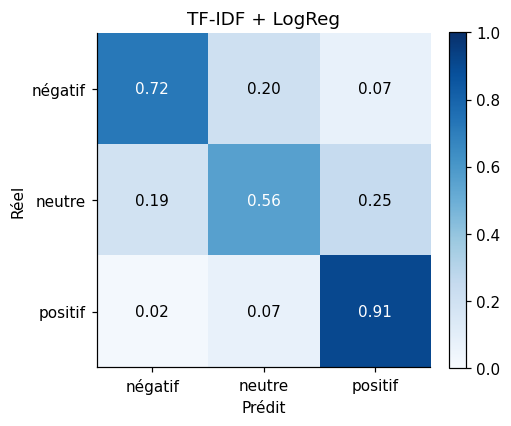

Mots qui poussent vers « négatif » : not good, not, yuck, two stars, terrible, nasty, awful, disgusting, horrible, worst, at all, gross, disappointing, bitter, not worth
Mots qui poussent vers « positif » : great, delicious, excellent, good, yummy, not too, perfect, yum, best, wonderful, nice, tasty, awesome, love this, fantastic


In [13]:
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    fig, ax = plt.subplots(figsize=(4.6, 4))
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(3): ax.text(j, i, f'{cm[i,j]:.2f}', ha='center', va='center', color='white' if cm[i,j] > .5 else 'black')
    ax.set_xlabel('Prédit'); ax.set_ylabel('Réel'); ax.set_title(title); plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()
plot_cm(y_test, pred_tfidf, 'TF-IDF + LogReg')

feat = np.array(tfidf.get_feature_names_out())
for c in [0, 2]:
    top = np.argsort(clf_tfidf.coef_[c])[::-1][:15]
    print(f'Mots qui poussent vers « {LABELS[c]} » :', ', '.join(feat[top]))

#### 🔎 Lecture du résultat
**Matrice** : la diagonale = le **rappel** de chaque classe (≈ 0,72 / 0,56 / 0,91). Les erreurs se font presque toujours **vers la classe adjacente** (négatif↔neutre, neutre↔positif), jamais d'un extrême à l'autre : le modèle comprend bien la polarité, il hésite seulement sur l'intensité.

**Mots discriminants (reproductibles)** :
- *Négatif* : « not good », « not », « yuck », « two stars », « terrible », « nasty », « awful », « disgusting », « worst », « disappointing », « not worth »…
- *Positif* : « great », « delicious », « excellent », « yummy », « perfect », « best », « wonderful », « tasty », « love this »…

Observations : (1) les **bigrammes** sont décisifs — « **not good** » et « **not worth** » sont parmi les meilleurs indicateurs négatifs, et un modèle sac-de-mots simple (unigrammes) les manquerait ; (2) « **not too** » apparaît côté positif (« not too sweet », « not too salty ») : un exemple où une négation **n'est pas** négative, que seul un modèle contextuel (BERT) peut vraiment démêler.

### 3.2 Embeddings de phrases (Transformer pré-entraîné)

**Idée du cours :** un *embedding contextuel* représente chaque avis par un vecteur dense qui capte le **sens** (contrairement à TF-IDF qui ne voit que des mots). Nous utilisons **`all-MiniLM-L6-v2`** (Sentence-BERT) : un Transformer encodeur de 22 M paramètres qui produit un vecteur de **384 dimensions** par texte.

- **`max_seq_length=128`** : on tronque à 128 tokens (la médiane des avis est ~56 mots → la grande majorité est couverte).
- **`normalize_embeddings=True`** : vecteurs de norme 1 → le produit scalaire = **similarité cosinus** (cf. cours : mesure de similarité).
- Ces embeddings sont calculés **une seule fois** pour tous les avis du *core* ; ils serviront ensuite à : la classification, le clustering de thèmes, les features des nœuds du GNN, la recommandation *content-based* et le **retriever** du Graph-RAG.

*Si la bibliothèque n'est pas disponible, une alternative non neuronale (TF-IDF + SVD) est utilisée automatiquement pour que le notebook reste exécutable.*

In [14]:
EMB_PATH = 'outputs/review_embeddings.npy'
texts = core.full_text.tolist()
if os.path.exists(EMB_PATH):
    emb = np.load(EMB_PATH); EMB_KIND = 'cache'
else:
    try:
        from sentence_transformers import SentenceTransformer
        st_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', device=device)
        st_model.max_seq_length = 128
        t0 = time.time()
        emb = st_model.encode(texts, batch_size=256, show_progress_bar=True, normalize_embeddings=True, convert_to_numpy=True)
        EMB_KIND = 'MiniLM'; print(f'Encodage terminé en {time.time()-t0:.0f}s')
    except Exception as e:
        print('sentence-transformers indisponible → repli TF-IDF + SVD :', e)
        from sklearn.decomposition import TruncatedSVD
        from sklearn.preprocessing import normalize
        svd_in = TfidfVectorizer(max_features=40000, min_df=3, stop_words='english', sublinear_tf=True).fit_transform(texts)
        emb = normalize(TruncatedSVD(128, random_state=SEED).fit_transform(svd_in)); EMB_KIND = 'SVD'
    np.save(EMB_PATH, emb.astype('float32'))
emb = emb.astype('float32')
print('Type :', EMB_KIND, '| Forme des embeddings :', emb.shape, '| norme moyenne :', np.linalg.norm(emb, axis=1).mean().round(3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/310 [00:00<?, ?it/s]

Encodage terminé en 114s
Type : MiniLM | Forme des embeddings : (79293, 384) | norme moyenne : 1.0


#### 🔎 Lecture du résultat
- **Type : MiniLM** confirme l'usage du Transformer pré-entraîné (si vous lisez `SVD`, c'est le repli sans sentence-transformers).
- **Forme `(79293, 384)`** : un vecteur de 384 nombres par avis ; **norme ≈ 1,000** car on a normalisé → produit scalaire = similarité cosinus.
- L'encodage est sauvegardé dans `outputs/review_embeddings.npy` : relancer le notebook le recharge instantanément (si le cache existe).
- Ces vecteurs sont la **matière première** de toute la suite (features GNN, clusters, recommandation, retriever).

### 3.3 Classification du sentiment sur embeddings
Même régression logistique, mais sur les vecteurs de 384 dimensions au lieu de 60 000 features creuses. Si le Transformer capte bien le sens, on obtient une représentation **compacte** (384 dim) tout aussi (ou plus) discriminante.

              precision    recall  f1-score   support

     négatif      0.462     0.673     0.548      1781
      neutre      0.303     0.572     0.396      1867
     positif      0.952     0.759     0.845     12211

    accuracy                          0.728     15859
   macro avg      0.572     0.668     0.596     15859
weighted avg      0.820     0.728     0.759     15859



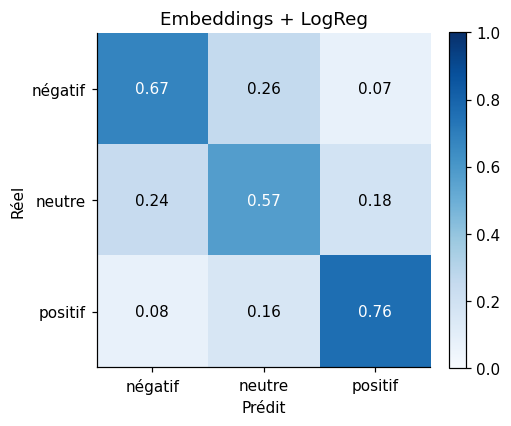

In [15]:
clf_emb = LogisticRegression(max_iter=1500, C=2, class_weight='balanced').fit(emb[train_idx], y_train)
pred_emb = clf_emb.predict(emb[test_idx])
log_result('Embeddings + LogReg', pred_emb)
print(classification_report(y_test, pred_emb, target_names=LABELS, digits=3))
plot_cm(y_test, pred_emb, 'Embeddings + LogReg')

#### 🔎 Lecture du résultat
Avec **MiniLM** (embeddings de 384 dimensions) et une régression logistique : **accuracy 0,728 / F1 macro 0,596** (négatif 0,548 ; neutre 0,396 ; positif 0,845), nettement sous TF-IDF (0,844 / 0,709). Le classifieur **sur-prédit les classes minoritaires** à cause de `class_weight='balanced'` : rappel élevé mais précision faible (négatif : rappel 0,67 / précision 0,46 ; neutre : rappel 0,57 / précision 0,30), tandis que 24 % des avis positifs sont classés à tort négatifs ou neutres (rappel positif 0,76).

Ce résultat n'a rien d'anormal : MiniLM est entraîné pour mesurer la **similarité sémantique** de phrases (deux avis parlant du même sujet auront des vecteurs proches, qu'ils soient positifs ou négatifs), pas spécifiquement la **polarité**. Les embeddings généralistes sont excellents pour *retrouver, regrouper, recommander* (usages des sections 4, 7, 8), et moins bons que le fine-tuning pour *classer le sentiment*. C'est précisément la motivation de la sous-section suivante.

**À regarder dans vos résultats :** le F1 de la classe *neutre* (0,396, point faible commun à tous les modèles) et la matrice de confusion.


### 3.4 Fine-tuning de DistilBERT (Chapitre 2 : Transformers / BERT)
Ici on **réentraîne** un Transformer encodeur complet (**DistilBERT**, version allégée de BERT : 66 M paramètres, ~40 % plus petit, ~60 % plus rapide) avec une tête de classification à 3 classes. C'est l'approche « *fine-tuning* » du cours (Ch.3) : le modèle pré-entraîné a déjà appris la langue ; on l'**adapte** à notre tâche avec peu de données.

Choix d'entraînement expliqués :
- **Sous-échantillon d'entraînement** (`FT_N` = 30 000 avis) et **2 époques** : compromis temps/qualité sur un GPU T4 (~6–8 min). L'évaluation se fait sur **tout** le jeu de test.
- **Perte pondérée** (poids inversement proportionnels à la fréquence des classes) : même rôle que `class_weight='balanced'`.
- **`lr=3e-5`**, **warm-up linéaire** puis décroissance : réglage standard pour BERT.
- **Précision mixte (AMP)** : calculs en float16 sur GPU pour accélérer ×2 sans perte notable.
- **Boucle d'entraînement écrite à la main** (plutôt que `Trainer`) pour être robuste aux changements de versions de la bibliothèque et pour voir exactement ce qui se passe.

*Sans GPU, mettez `RUN_BERT = False` : le notebook continue sans cette partie.*

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


époque 1/2 | pas 200/1876 | perte 0.2527 | 23s
époque 1/2 | pas 400/1876 | perte 0.7672 | 47s
époque 1/2 | pas 600/1876 | perte 1.0661 | 73s
époque 1/2 | pas 800/1876 | perte 0.2654 | 99s
époque 2/2 | pas 1000/1876 | perte 0.3362 | 123s
époque 2/2 | pas 1200/1876 | perte 0.4078 | 149s
époque 2/2 | pas 1400/1876 | perte 0.7309 | 174s
époque 2/2 | pas 1600/1876 | perte 0.4344 | 199s
époque 2/2 | pas 1800/1876 | perte 0.3547 | 225s
              precision    recall  f1-score   support

     négatif      0.739     0.745     0.742      1781
      neutre      0.427     0.675     0.523      1867
     positif      0.970     0.883     0.924     12211

    accuracy                          0.843     15859
   macro avg      0.712     0.768     0.730     15859
weighted avg      0.880     0.843     0.856     15859



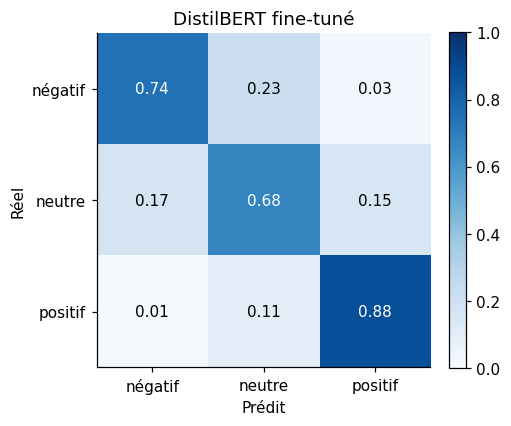

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [16]:
if RUN_BERT and HAS_TORCH and device == 'cuda':
    import torch.nn as nn
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    MODEL, FT_N, EPOCHS, BS, LR, MAXLEN = 'distilbert-base-uncased', 30000, 2, 32, 3e-5, 128
    tok = AutoTokenizer.from_pretrained(MODEL)
    bert = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3).to(device)
    rng = np.random.RandomState(SEED)
    ft_idx = rng.choice(train_idx, size=min(FT_N, len(train_idx)), replace=False)
    ft_texts, ft_y = core.full_text.values[ft_idx], core.label.values[ft_idx]

    cls_freq = np.bincount(ft_y, minlength=3) / len(ft_y)
    class_w = torch.tensor(1.0 / cls_freq / (1.0 / cls_freq).sum() * 3, dtype=torch.float, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=class_w)
    opt = torch.optim.AdamW(bert.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * int(np.ceil(len(ft_idx) / BS))
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    scaler = torch.cuda.amp.GradScaler()

    def batchify(txts):
        return {k: v.to(device) for k, v in tok(list(txts), truncation=True, max_length=MAXLEN, padding=True, return_tensors='pt').items()}

    t0, step = time.time(), 0
    for ep in range(EPOCHS):
        bert.train(); perm = rng.permutation(len(ft_idx))
        for i in range(0, len(perm), BS):
            b = perm[i:i+BS]
            enc = batchify(ft_texts[b]); yb = torch.tensor(ft_y[b], device=device)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = loss_fn(bert(**enc).logits.float(), yb)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(bert.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step(); step += 1
            if step % 200 == 0: print(f'époque {ep+1}/{EPOCHS} | pas {step}/{steps} | perte {loss.item():.4f} | {time.time()-t0:.0f}s')

    # évaluation sur TOUT le jeu de test
    bert.eval(); preds = []
    test_txt = core.full_text.values[test_idx]
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for i in range(0, len(test_txt), 128):
            preds.append(bert(**batchify(test_txt[i:i+128])).logits.argmax(-1).cpu().numpy())
    pred_bert = np.concatenate(preds)
    log_result('DistilBERT fine-tuné', pred_bert)
    print(classification_report(y_test, pred_bert, target_names=LABELS, digits=3))
    plot_cm(y_test, pred_bert, 'DistilBERT fine-tuné')
    bert.save_pretrained('outputs/distilbert_sentiment'); tok.save_pretrained('outputs/distilbert_sentiment')
else:
    print('Fine-tuning BERT ignoré (RUN_BERT=False ou pas de GPU).')

#### 🔎 Lecture du résultat
- La **perte** affichée tous les 200 pas doit **décroître** (en général de ~1,0 vers ~0,5). Une perte qui stagne signalerait un `lr` trop faible/fort.
- **Résultat attendu :** le fine-tuning est la méthode qui **adapte le Transformer lui-même à la tâche** ; on s'attend à ce qu'il dépasse les deux autres approches, **surtout sur la classe neutre**, car il lit chaque mot **en contexte** (il distingue « not good » de « not too sweet »). Comparez les F1 par classe avec TF-IDF (0,70 / 0,50 / 0,93).
- Le modèle est sauvegardé dans `outputs/distilbert_sentiment` : il peut être rechargé directement (`AutoModelForSequenceClassification.from_pretrained`), c'est le **modèle de classification** livrable.
- Si le GPU est absent ou `RUN_BERT=False`, cette partie est simplement sautée.

### 3.5 Comparaison des trois approches
Tableau et graphique de synthèse sur le **même jeu de test**. On compare surtout le **F1 macro** et le **F1 de la classe neutre**.

,accuracy,f1_macro,f1_négatif,f1_neutre,f1_positif
TF-IDF + LogReg,0.844,0.709,0.699,0.502,0.927
Embeddings + LogReg,0.728,0.596,0.548,0.396,0.845
DistilBERT fine-tuné,0.843,0.730,0.742,0.523,0.924


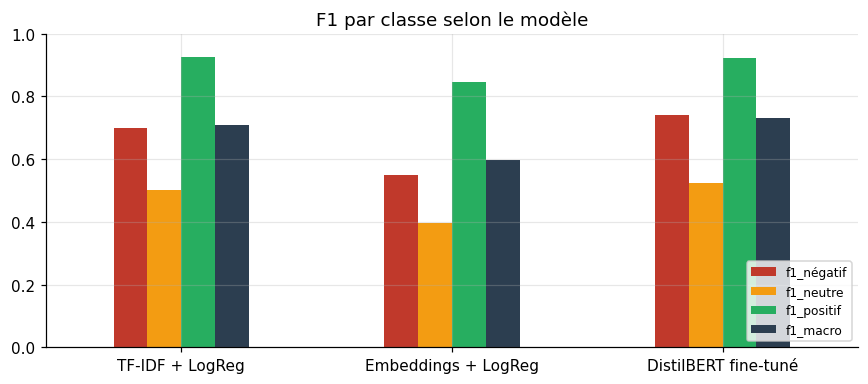

In [17]:
res = pd.DataFrame(results_sent).T.round(3)
display(res)
fig, ax = plt.subplots(figsize=(8, 3.6))
res[['f1_négatif', 'f1_neutre', 'f1_positif', 'f1_macro']].plot.bar(ax=ax, rot=0, color=['#c0392b', '#f39c12', '#27ae60', '#2c3e50'])
ax.set_ylim(0, 1); ax.set_title('F1 par classe selon le modèle'); ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

#### 🔎 Lecture du tableau de synthèse
| Modèle | Accuracy | F1 macro | F1 négatif | F1 neutre | F1 positif |
|---|---|---|---|---|---|
| TF-IDF + LogReg | 0,844 | 0,709 | 0,699 | 0,502 | 0,927 |
| Embeddings (MiniLM) + LogReg | 0,728 | 0,596 | 0,548 | 0,396 | 0,845 |
| DistilBERT fine-tuné | 0,843 | **0,730** | **0,742** | **0,523** | 0,924 |

- **DistilBERT obtient le meilleur F1 macro** (+0,021 par rapport à TF-IDF), grâce aux classes minoritaires (négatif +0,043, neutre +0,021). Son accuracy est identique à celle de TF-IDF (0,843 contre 0,844) car elle est dominée par la classe positive, où les deux modèles sont équivalents (0,924 contre 0,927).
- **Le gain reste modeste** et provient d'une seule exécution (une graine, un découpage) : à présenter comme « légèrement meilleur », pas comme une rupture. TF-IDF est une baseline **très compétitive**, pour un coût et une interprétabilité bien meilleurs.
- **Les embeddings MiniLM généralistes sont les moins bons** : ils encodent le *sujet* plus que la *polarité* (voir 3.3).
- La classe **neutre** reste la plus difficile pour tous les modèles (F1 ≤ 0,52).

**Comment conclure :** comparer les **F1 macro** (qui pèsent chaque classe pareil) plutôt que l'accuracy (dominée par la classe positive). Un bon récit pour l'oral : *TF-IDF (simple, interprétable, déjà très bon) → embeddings généralistes (utiles pour regrouper et chercher, pas pour la polarité) → fine-tuning (meilleur F1 macro, mais coût GPU)* — le compromis **performance / coût / interprétabilité** du cours.


## 4. Découverte de thèmes (NLP non supervisé)

Deux techniques complémentaires, toutes deux vues en cours :
- **LDA** (*Latent Dirichlet Allocation*) : un **document** est une distribution de probabilités sur des **topics**, et un **topic** est une distribution sur des **mots**. Méthode classique, très interprétable (liste de mots).
- **Clustering des embeddings (K-Means)** : regroupe les avis **sémantiquement proches** ; on étiquette chaque cluster par ses mots TF-IDF les plus caractéristiques.

### 4.1 LDA — pipeline du cours
`Nettoyage → vectorisation Bag-of-Words → LDA (K topics)`.
- `CountVectorizer` avec `stop_words='english'` (ici le pré-traitement lourd est pertinent), `max_df=0.5` (on retire les mots présents dans plus de la moitié des avis : trop génériques) et `min_df=20` (on retire les mots trop rares).
- `K = 8` topics, `learning_method='online'` (rapide sur grands corpus).
- On travaille sur un échantillon de 40 000 avis (LDA est coûteux ; l'échantillon suffit à dégager les grands thèmes).

In [18]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

lda_sample = core.sample(min(40000, len(core)), random_state=SEED)
cv = CountVectorizer(stop_words='english', max_df=0.5, min_df=20, max_features=20000, token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
Xcv = cv.fit_transform(lda_sample.full_text)
K_TOPICS = 8
lda = LatentDirichletAllocation(n_components=K_TOPICS, learning_method='online', random_state=SEED, max_iter=10, n_jobs=-1).fit(Xcv)
vocab = np.array(cv.get_feature_names_out())
topic_words = {}
for k, comp in enumerate(lda.components_):
    topic_words[k] = vocab[np.argsort(comp)[::-1][:12]]
    print(f'Topic {k} :', ', '.join(topic_words[k]))

Topic 0 : tea, like, drink, taste, flavor, water, hair, good, sweet, juice, sugar, green
Topic 1 : like, taste, good, snack, great, flavor, sweet, just, chocolate, cookies, cereal, really
Topic 2 : salt, vanilla, rice, low, soup, meal, add, easy, flavor, tasty, good, okay
Topic 3 : great, price, amazon, good, product, love, best, buy, store, bag, box, organic
Topic 4 : food, dog, dogs, treats, like, eat, cat, cats, treat, chicken, good, loves
Topic 5 : just, product, like, coconut, did, don, use, used, know, didn, try, bread
Topic 6 : coffee, like, flavor, cup, taste, good, just, water, great, really, use, make
Topic 7 : chocolate, fat, calories, oil, sauce, protein, serving, butter, candy, high, dark, taste


> ℹ️ *Le LDA ne dépend pas des embeddings ; thèmes relevés avec `random_state=42` (de légères variations d'ordre sont possibles selon la version de scikit-learn).*

#### 🔎 Lecture des 8 thèmes
| Topic | Mots dominants | Interprétation |
|---|---|---|
| 0 | tea, drink, water, hair, juice, ginger, green, bottle | **Boissons / thé** (et produits « hair » : shampoings au tea-tree, présents dans la catégorie) |
| 1 | cookies, cereal, gluten, free, rice, mix, chips | **Biscuits, céréales, sans gluten** |
| 2 | low, salt, snack, soup, meal, easy | **Snacks et plats rapides / allégés** |
| 3 | price, amazon, buy, store, bought, best | **Achat et prix** — thème *non culinaire* : on parle du vendeur et du rapport qualité/prix |
| 4 | food, dog, dogs, treats, cat, cats | **Animaux (chiens/chats)** |
| 5 | like, taste, just, really, don, didn, bad, think | **Opinion générale / déception** (« didn't like », « don't think ») |
| 6 | coffee, cup, flavor, hot, sauce, strong | **Café** (et sauces) |
| 7 | chocolate, calories, fat, bars, sugar, butter, coconut | **Chocolat, barres, nutrition** |

LDA retrouve des **thèmes sémantiquement cohérents** sans aucune étiquette. Un thème « bruit » (3, achat/prix) et un thème « opinion » (5) sont typiques : LDA capture aussi des *registres* de langage, pas seulement des sujets.

#### Lien thème ↔ sentiment
Pour chaque avis on prend son **topic dominant** (celui de probabilité maximale), puis on regarde la **note moyenne par topic** et le **poids** de chaque topic dans le corpus. Cela répond à : *« de quoi parle-t-on le plus, et dans quels thèmes les clients sont-ils les plus (in)satisfaits ? »*

,part,note_moyenne,pct_negatif,mots_cles
topic,,,,
0,0.160,3.961,0.128,"tea, like, drink, taste, flavor"
1,0.262,4.196,0.096,"like, taste, good, snack, great"
2,0.030,4.322,0.077,"salt, vanilla, rice, low, soup"
3,0.152,4.520,0.070,"great, price, amazon, good, product"
4,0.104,4.159,0.121,"food, dog, dogs, treats, like"
5,0.062,3.495,0.305,"just, product, like, coconut, did"
6,0.181,4.170,0.096,"coffee, like, flavor, cup, taste"
7,0.048,4.141,0.111,"chocolate, fat, calories, oil, sauce"


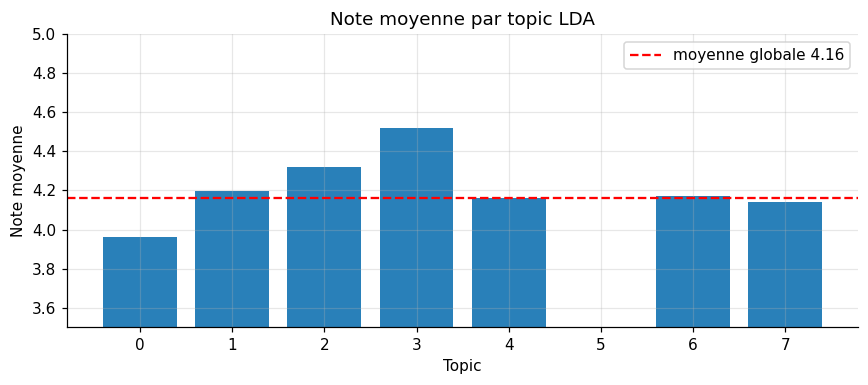

In [19]:
doc_topic = lda.transform(Xcv)
lda_sample = lda_sample.assign(topic=doc_topic.argmax(1))
tstats = lda_sample.groupby('topic').agg(part=('Score', lambda s: len(s)/len(lda_sample)), note_moyenne=('Score', 'mean'), pct_negatif=('label', lambda s: (s == 0).mean()))
tstats['mots_cles'] = [', '.join(topic_words[k][:5]) for k in tstats.index]
display(tstats.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(tstats.index.astype(str), tstats.note_moyenne, color='#2980b9'); ax.set_ylim(3.5, 5); ax.set_xlabel('Topic'); ax.set_ylabel('Note moyenne')
ax.axhline(core.Score.mean(), color='red', ls='--', label=f'moyenne globale {core.Score.mean():.2f}'); ax.legend(); ax.set_title('Note moyenne par topic LDA'); plt.tight_layout(); plt.show()

#### 🔎 Lecture du tableau
- **Topic 5 (opinion/déception : « just, product, like, did »)** : note moyenne **3,50** et **30,5 % d'avis négatifs**, contre 3,96–4,52 pour les autres → c'est le **thème de l'insatisfaction**. LDA a donc isolé *automatiquement* les avis négatifs sous forme de thème, sans voir les notes : forte cohérence texte ↔ note.
- **Topics 3 (prix/achat) et 2 (sel, vanille, riz, soupe)** sont les plus satisfaits (notes 4,52 et 4,32) avec seulement 7,0 % et 7,7 % de négatifs : les gens parlent de prix et d'achat surtout quand tout s'est bien passé.
- **Topic 4 (animaux)** a 12,1 % d'avis négatifs et **topic 0 (thé/boissons)** 12,8 % avec la note la plus basse après le topic 5 (3,96) : les acheteurs sont plus exigeants sur leur animal, et les boissons sont une catégorie plus critiquée (même constat qu'avec les clusters K-Means en 4.2).
- **Poids** : le topic 1, générique (« like, taste, good, snack »), pèse 26 % ; puis café 18 %, thé/boissons 16 %, prix 15 %, animaux 10 %.


### 4.2 Clustering des embeddings (K-Means)
On applique **MiniBatch K-Means** (version rapide de K-Means) aux embeddings des avis, avec **K = 10** clusters. Chaque cluster est décrit par les mots dont le **TF-IDF moyen** est le plus élevé dans ses avis (« mots-clés du cluster »).

La **silhouette** (calculée sur un échantillon de 5 000 avis, car coûteuse) mesure la séparation des clusters (entre −1 et 1 ; >0.1 est déjà correct en grande dimension, car les embeddings de textes forment un continuum plutôt que des groupes nets).

In [20]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

K_CL = 10
km = MiniBatchKMeans(n_clusters=K_CL, random_state=SEED, batch_size=4096, n_init=5).fit(emb)
core['cluster'] = km.labels_
sil = silhouette_score(emb[np.random.RandomState(SEED).choice(len(emb), 5000, replace=False)], km.labels_[np.random.RandomState(SEED).choice(len(emb), 5000, replace=False)])
print(f'Silhouette (échantillon 5 000) : {sil:.3f}\n')

tfv = TfidfVectorizer(max_features=30000, stop_words='english', min_df=10, sublinear_tf=True, token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
T_all = tfv.fit_transform(core.full_text)           # matrice TF-IDF de tous les avis (réutilisée plus loin)
tf_vocab = np.array(tfv.get_feature_names_out())
def top_terms(mask, n=8):
    m = np.asarray(T_all[np.where(mask)[0]].mean(axis=0)).ravel()
    return ', '.join(tf_vocab[np.argsort(m)[::-1][:n]])
rows = [dict(cluster=c, taille=int((core.cluster == c).sum()), note_moy=round(core.Score[core.cluster == c].mean(), 2), mots_cles=top_terms((core.cluster == c).values)) for c in range(K_CL)]
cl_df = pd.DataFrame(rows).sort_values('taille', ascending=False); display(cl_df)

Silhouette (échantillon 5 000) : 0.045



,cluster,taille,note_moy,mots_cles
3,3,13714,4.26,"snack, great, good, like, taste, love, bars, just"
4,4,13205,3.94,"taste, flavor, like, drink, sugar, water, good..."
6,6,11393,4.22,"sauce, good, soup, great, like, flavor, pasta,..."
1,1,8611,4.12,"coffee, cup, flavor, good, like, taste, strong..."
2,2,7219,4.14,"dog, dogs, food, treats, cat, cats, loves, treat"
7,7,6336,4.22,"tea, teas, green, flavor, drink, like, taste, ..."
9,9,6231,4.29,"cereal, good, granola, milk, like, great, swee..."
8,8,4709,4.44,"gluten, free, bread, mix, great, flour, wheat,..."
5,5,4411,4.07,"cookies, cookie, chocolate, like, taste, good,..."
0,0,3464,4.01,"hair, shampoo, conditioner, product, scalp, oi..."


#### 🔎 Lecture du résultat
- **Silhouette ≈ 0,05 (0,045)** : faible, mais **normale** pour des embeddings de texte, qui forment un *continuum* de sujets plutôt que des îlots séparés. Elle indique que les frontières sont floues, pas que le clustering est inutile : l'important est que les **mots-clés** de chaque cluster soient cohérents.
- Les 10 clusters correspondent à des **familles de produits nettes** : *snacks/barres* (13 714 avis), *boissons* (sugar, water, drink ; 13 205), *sauces/soupes/pâtes* (11 393), *café* (8 611), *chiens et chats* (7 219), *thé* (6 336), *céréales/granola* (6 231), *sans gluten/pain/farine* (4 709), *biscuits/chocolat* (4 411) et un cluster **hors alimentaire** (*hair, shampoo, conditioner* ; 3 464 avis) : le jeu de données contient aussi quelques produits de soin.
- **Note moyenne par cluster** : le cluster **boissons** est le moins bien noté (**3,94**), suivi du cluster soin (4,01) et des biscuits (4,07) ; le cluster **sans gluten** est le mieux noté (**4,44**).
- Comparez avec LDA (4.1) : deux méthodes **indépendantes** (probabiliste vs géométrique) retrouvent les **mêmes grandes familles** (café, thé, animaux, boissons, snacks) → les thèmes sont réels, pas des artefacts.


## 5. Construction du graphe utilisateurs–produits (Chapitre 1 : graphes)

### 5.1 Définition formelle
Selon la typologie du cours, notre graphe est :
- **biparti** : deux types de nœuds (**utilisateurs** `U:…` et **produits** `P:…`), les arêtes relient *toujours* un utilisateur à un produit → c'est un graphe **hétérogène** (deux types de nœuds) ;
- **pondéré** : le poids de l'arête = la **note** (1–5) ; on stocke aussi la classe de sentiment ;
- **non orienté** pour l'analyse structurelle.

`G.add_edge(U, P, weight=Score)` crée automatiquement les deux nœuds s'ils n'existent pas.

Nœuds : 21,490 (13,118 utilisateurs + 8,372 produits) | Arêtes : 79,293
Densité : 0.00034 | Composantes connexes : 2
Degré utilisateur : moy=6.0 méd=4 max=174 | Degré produit : moy=9.5 méd=5 max=472
Biparti ? True


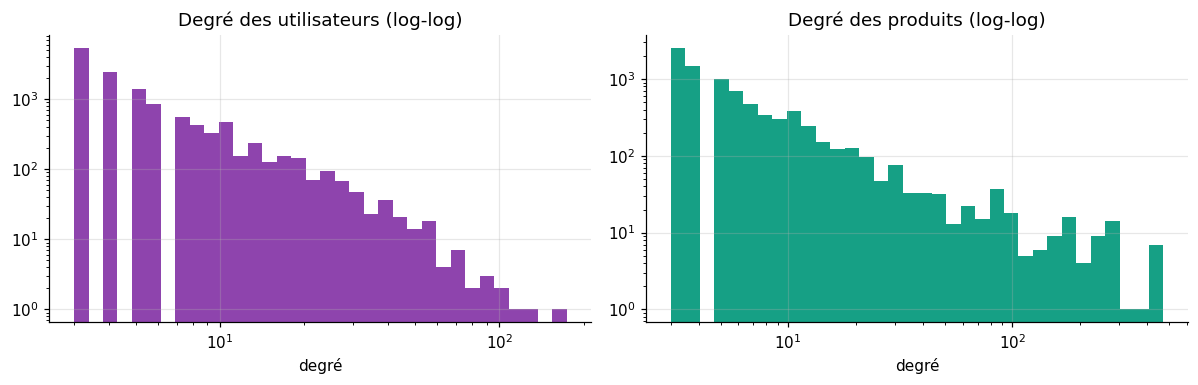

In [21]:
G = nx.Graph()
users_nodes = ['U:' + u for u in user_ids]; prods_nodes = ['P:' + p for p in prod_ids]
G.add_nodes_from(users_nodes, kind='user'); G.add_nodes_from(prods_nodes, kind='product')
G.add_edges_from(zip('U:' + core.UserId, 'P:' + core.ProductId, [dict(weight=int(s), sentiment=int(l)) for s, l in zip(core.Score, core.label)]))

deg = dict(G.degree())
ud = np.array([deg[n] for n in users_nodes]); pdg = np.array([deg[n] for n in prods_nodes])
print(f'Nœuds : {G.number_of_nodes():,} ({n_users:,} utilisateurs + {n_prods:,} produits) | Arêtes : {G.number_of_edges():,}')
print(f'Densité : {nx.density(G):.5f} | Composantes connexes : {nx.number_connected_components(G)}')
print(f'Degré utilisateur : moy={ud.mean():.1f} méd={np.median(ud):.0f} max={ud.max()} | Degré produit : moy={pdg.mean():.1f} méd={np.median(pdg):.0f} max={pdg.max()}')
print('Biparti ?', nx.is_bipartite(G))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, d, c, t in zip(ax, [ud, pdg], ['#8e44ad', '#16a085'], ['Degré des utilisateurs', 'Degré des produits']):
    a.hist(d, bins=np.logspace(np.log10(d.min()), np.log10(d.max()), 35), color=c); a.set_xscale('log'); a.set_yscale('log'); a.set_title(t + ' (log-log)'); a.set_xlabel('degré')
plt.tight_layout(); plt.show()

#### 🔎 Lecture du résultat (reproductible)
- **21 490 nœuds** (13 118 utilisateurs + 8 372 produits) et **79 293 arêtes** : une arête = un avis.
- **Densité 0,00034** : seuls 0,03 % des paires utilisateur–produit possibles sont observées → graphe très **creux**.
- **2 composantes connexes** : presque tout le graphe forme une **composante géante** → l'information peut se propager entre presque tous les nœuds (condition nécessaire au GNN et au filtrage collaboratif).
- **Degrés** : utilisateurs moy. **6,0** / médiane **4** / max **174** ; produits moy. **9,5** / médiane **5** / max **472**. Moyenne ≫ médiane = distribution **à queue lourde** : quelques **hubs** (produits best-sellers, utilisateurs très actifs) et une multitude de nœuds peu connectés (graphiques log-log quasi linéaires).
- `is_bipartite = True` confirme qu'aucune arête ne relie deux nœuds du même type.

### 5.2 Détection de communautés (Louvain)
**But :** trouver des groupes d'utilisateurs et de produits **fortement connectés entre eux** (des « goûts communs »).

**Algorithme de Louvain** : maximise la **modularité** *Q* (écart entre la densité de liens dans les groupes et celle attendue au hasard). Q ∈ [−0.5, 1] ; Q > 0.3 indique une structure communautaire significative.

**Choix de conception important :** on ne garde que les **arêtes positives** (note ≥ 4) pour la détection. Raison : un avis *négatif* ne signifie pas que deux utilisateurs « partagent des goûts » — au contraire, relier deux utilisateurs via un produit qu'ils ont détesté mélangerait les communautés. Le poids de l'arête est la note/5.

On décrit ensuite chaque communauté : nombre d'utilisateurs/produits, **note moyenne**, et **mots-clés** (TF-IDF des avis de ses produits).

In [22]:
core_pos = core[core.Score >= 4]
Gpos = nx.Graph()
Gpos.add_weighted_edges_from(zip('U:' + core_pos.UserId, 'P:' + core_pos.ProductId, core_pos.Score / 5.0))
t0 = time.time()
comms = nx.community.louvain_communities(Gpos, weight='weight', resolution=1.0, seed=SEED)
comms = sorted(comms, key=len, reverse=True)
Q = nx.community.modularity(Gpos, comms, weight='weight')
print(f'Graphe positif : {Gpos.number_of_nodes():,} nœuds, {Gpos.number_of_edges():,} arêtes')
print(f'{len(comms)} communautés trouvées en {time.time()-t0:.1f}s | modularité Q = {Q:.3f}')
print('Tailles des 12 plus grandes :', [len(c) for c in comms[:12]])

node_comm = {n: i for i, c in enumerate(comms) for n in c}
core['u_comm'] = ('U:' + core.UserId).map(node_comm); core['p_comm'] = ('P:' + core.ProductId).map(node_comm)
big = [i for i, c in enumerate(comms) if len(c) >= 100][:12]      # on décrit les 12 plus grandes communautés (triées par taille)
prof = []
for i in big:
    m = (core.p_comm == i).values
    prof.append(dict(communaute=i, utilisateurs=sum(n.startswith('U:') for n in comms[i]), produits=sum(n.startswith('P:') for n in comms[i]),
                     avis=int(m.sum()), note_moy=round(core.Score[m].mean(), 2), mots_cles=top_terms(m)))
comm_df = pd.DataFrame(prof); display(comm_df)

Graphe positif : 21,196 nœuds, 61,054 arêtes
34 communautés trouvées en 5.0s | modularité Q = 0.562
Tailles des 12 plus grandes : [2838, 2696, 2018, 1931, 1884, 1657, 1238, 1016, 650, 566, 562, 433]


,communaute,utilisateurs,produits,avis,note_moy,mots_cles
0,0,2531,307,23996,3.85,"like, taste, good, flavor, just, coffee, drink..."
1,1,1616,1080,8870,4.36,"gluten, free, great, good, like, taste, love, ..."
2,2,1020,998,6211,4.30,"good, great, like, taste, just, price, flavor,..."
3,3,1021,910,6183,4.32,"tea, good, great, like, love, taste, flavor, just"
4,4,1071,813,6041,4.38,"great, good, love, like, organic, taste, baby,..."
5,5,1026,631,5552,4.21,"coffee, cup, cups, good, like, great, flavor, ..."
6,6,737,501,3549,4.27,"dog, dogs, treats, food, love, loves, great, good"
7,7,558,458,2807,4.34,"tea, great, good, taste, like, love, flavor, just"
8,8,360,290,1857,4.23,"soup, good, like, great, taste, tea, flavor, love"
9,9,328,238,1563,4.32,"coffee, good, great, taste, like, tea, flavor,..."


#### 🔎 Lecture du résultat (Louvain, graphe des avis positifs)
- **Graphe positif** : 21 196 nœuds, 61 054 arêtes (on perd les avis ≤ 3★).
- **34 communautés**, **modularité Q = 0,562**. Repère : Q > 0,3 = structure communautaire significative ; **0,56 est élevé** → le graphe contient des groupes d'utilisateurs/produits **fortement cohésifs**.
- **Tailles des 12 plus grandes** : 2 838, 2 696, 2 018, 1 931, 1 884, 1 657, 1 238, 1 016, 650, 566, 562, 433 : quelques grands blocs puis une longue décroissance de niches.
- **Profil (mots-clés TF-IDF des avis)** — exemples parmi les 12 plus grandes : *sans gluten* (C1), *thé* (C3, C7, C10), *bébé/bio* (C4), *café en dosettes* (C5 : cup, cups, keurig), *chiens* (C6), *soupes* (C8), *café/thé* (C9), *chips/cacahuètes* (C11).
- **Un résultat intéressant :** la communauté C5 regroupe l'**écosystème des dosettes** (keurig, cups), alors que le texte seul (section 4.2) range tout le café dans un seul cluster. C'est de la **structure d'usage** que seul le graphe révèle : un utilisateur qui possède une machine à dosettes n'achète que des dosettes.
- **La plus grande communauté (C0) est atypique :** 2 531 utilisateurs autour de seulement 307 produits (≈ 78 avis par produit) et la note moyenne la plus basse (3,85) : un groupe de gros produits très commentés (café, boissons) plutôt qu'une niche.
- Plusieurs communautés ont des mots-clés génériques (« good, great, like ») : elles regroupent de nombreux produits variés autour d'utilisateurs « touche-à-tout » — limite à citer.


#### Validation croisée : les communautés du graphe correspondent-elles aux thèmes du texte ?
Test de cohérence **graphe ↔ texte** : si les communautés (issues **uniquement des liens**) coïncident avec les clusters (issus **uniquement du texte**), cela montre que les deux vues se **renforcent**.
On mesure l'accord avec la **NMI** (*Normalized Mutual Information*, 0 = indépendant, 1 = identique) entre communauté et cluster d'embedding, au niveau des avis, et on affiche la **table de contingence** (part de chaque cluster texte dans chaque communauté).

NMI(communauté produit, cluster texte) = 0.100


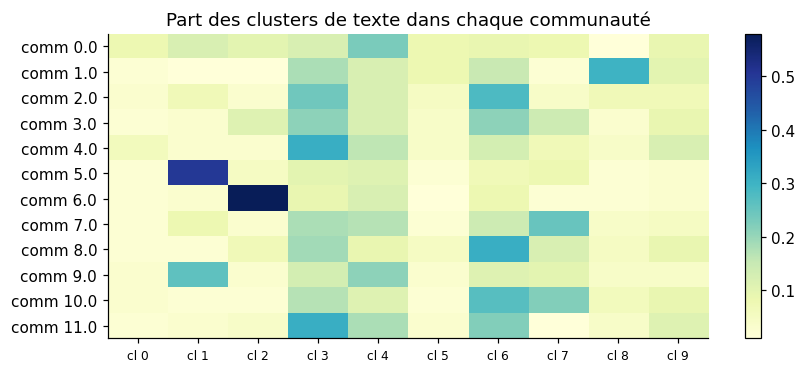

In [23]:
from sklearn.metrics import normalized_mutual_info_score as nmi
m = core.p_comm.isin(big)
print(f'NMI(communauté produit, cluster texte) = {nmi(core.p_comm[m], core.cluster[m]):.3f}')
ct = pd.crosstab(core.p_comm[m], core.cluster[m], normalize='index').round(2)
fig, ax = plt.subplots(figsize=(8, 3.5)); im = ax.imshow(ct.values, cmap='YlGnBu', aspect='auto'); ax.grid(False)
ax.set_yticks(range(len(ct))); ax.set_yticklabels([f'comm {i}' for i in ct.index]); ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels([f'cl {c}' for c in ct.columns], fontsize=8)
ax.set_title('Part des clusters de texte dans chaque communauté'); plt.colorbar(im); plt.tight_layout(); plt.show()

#### 🔎 Lecture du résultat
**NMI = 0,100** : faible, et c'est **cohérent** : les communautés du graphe (34, de granularité fine : usage, régime, type de produit) et les clusters texte (10, grandes familles) n'ont pas la même **granularité**, et la NMI pénalise ce décalage. La table de contingence (heatmap ci-dessus) permet de voir comment une communauté se répartit sur plusieurs clusters texte plutôt que de coïncider avec un seul.

**Conclusion :** graphe et texte sont **complémentaires** et non redondants — chaque vue apporte une information que l'autre n'a pas. C'est l'argument central du projet pour **combiner NLP et graphes**.


### 5.3 Visualisation d'un sous-graphe
Afficher 80 000 arêtes est illisible. On trace un **sous-graphe représentatif** : pour les 4 plus grandes communautés, les 12 produits les plus connectés et 5 de leurs utilisateurs. Couleur = communauté ; **carré = produit**, **rond = utilisateur** ; taille ∝ degré.

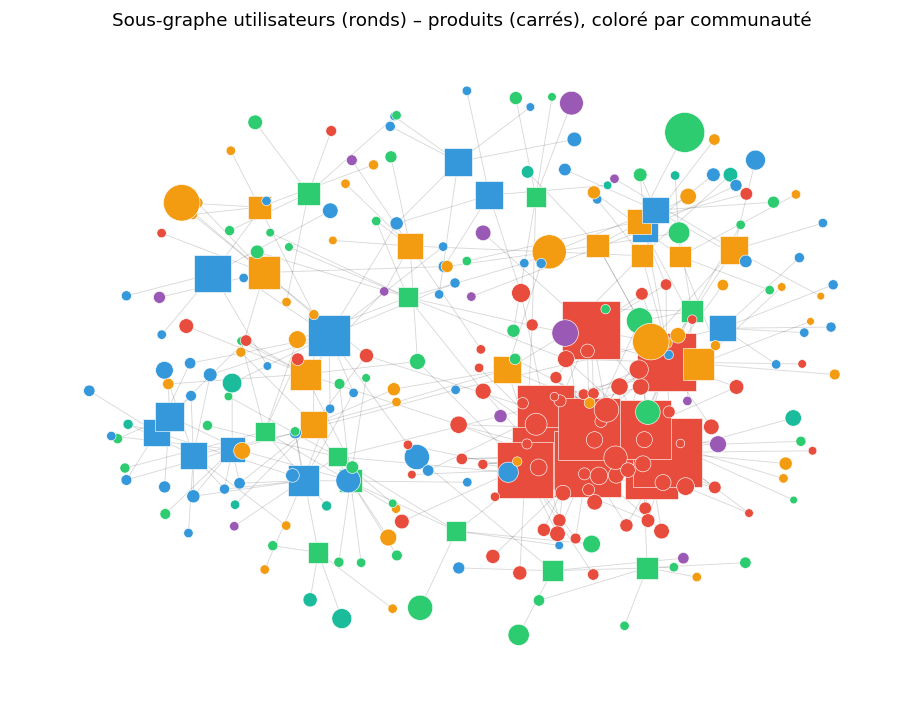

In [24]:
import random
random.seed(SEED)
sel = set()
for i in range(min(4, len(comms))):
    ps = sorted([n for n in comms[i] if n.startswith('P:')], key=lambda n: -Gpos.degree(n))[:12]
    for p in ps:
        sel.add(p); sel.update(random.sample([u for u in Gpos.neighbors(p)], min(5, Gpos.degree(p))))
H = Gpos.subgraph(sel)
pos = nx.spring_layout(H, seed=SEED, k=0.35, iterations=80)
palette = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']
fig, ax = plt.subplots(figsize=(8.5, 6.5)); nx.draw_networkx_edges(H, pos, alpha=.15, width=.6, ax=ax)
for kind, shape in [('P', 's'), ('U', 'o')]:
    nodes = [n for n in H if n.startswith(kind + ':')]
    nx.draw_networkx_nodes(H, pos, nodelist=nodes, node_shape=shape, node_size=[20 + 6 * Gpos.degree(n) for n in nodes],
                           node_color=[palette[node_comm[n] % len(palette)] for n in nodes], ax=ax, edgecolors='white', linewidths=.4)
ax.set_title('Sous-graphe utilisateurs (ronds) – produits (carrés), coloré par communauté'); ax.axis('off'); plt.tight_layout(); plt.show()
nx.write_gexf(G, 'outputs/graph_user_product.gexf')   # export pour Gephi

#### 🔎 Lecture du graphique
Chaque **couleur** = une communauté. On observe des **amas de produits (carrés)** entourés de leurs utilisateurs (ronds) : des produits d'une même communauté partagent les mêmes acheteurs. Les gros nœuds sont les **hubs**. Les quelques liens entre amas de couleurs différentes sont des utilisateurs « ponts » qui achètent dans plusieurs univers — ce sont eux qui rendent la recommandation inter-catégories possible.
Le fichier `outputs/graph_user_product.gexf` permet d'explorer le **graphe complet** dans Gephi (livrable *« graphe avec clusters »*).

## 6. Prédiction de notes par GNN et Graph Transformer Network (Chapitre 2)

### 6.1 Formulation du problème
**Tâche :** *prédiction d'arête (régression)* — étant donné un utilisateur *u* et un produit *p* **sans** avoir lu son avis, prédire la note *r(u,p)*. C'est le cœur d'un système de recommandation.

**Protocole sans fuite :**
- les **arêtes de test sont retirées du graphe** (le modèle ne les voit jamais, ni leur note, ni leur texte) ;
- les **features des nœuds** sont la **moyenne des embeddings** des avis *du train* de l'utilisateur / du produit ;
- à chaque époque d'entraînement, **20 % des arêtes train sont masquées** (ce sont celles à prédire) et retirées du passage de messages, comme le fera le test.

### 6.2 Baselines non-graphe (obligatoires pour juger l'apport du GNN)
- **Moyenne globale** : prédire toujours la même note.
- **Modèle à biais** : `r̂ = μ + b_u + b_p` (note moyenne + biais de l'utilisateur « généreux/sévère » + biais du produit « bien/mal noté »), avec régularisation λ. C'est une baseline **très forte** en recommandation (classique du challenge Netflix).

Métriques : **RMSE** (pénalise les grosses erreurs), **MAE**, **accuracy sur la note arrondie**.

In [25]:
def reg_metrics(y, p):
    p = np.clip(p, 1, 5)
    return dict(RMSE=float(np.sqrt(np.mean((y - p) ** 2))), MAE=float(np.mean(np.abs(y - p))), acc_arrondie=float(np.mean(np.round(p) == y)))

y_all_np = core.Score.values.astype(float)
y_te = y_all_np[test_idx]
mu = y_all_np[train_idx].mean()

def fit_bias(tr_ids, lam_u=5.0, lam_p=5.0):
    u, p, r = core.uid.values[tr_ids], core.pid.values[tr_ids], y_all_np[tr_ids]
    bu, bp = np.zeros(n_users), np.zeros(n_prods)
    for _ in range(10):   # moindres carrés alternés régularisés
        bp = np.bincount(p, weights=r - mu - bu[u], minlength=n_prods) / (np.bincount(p, minlength=n_prods) + lam_p)
        bu = np.bincount(u, weights=r - mu - bp[p], minlength=n_users) / (np.bincount(u, minlength=n_users) + lam_u)
    return bu, bp
bu, bp = fit_bias(train_idx)
pred_bias = mu + bu[core.uid.values[test_idx]] + bp[core.pid.values[test_idx]]

results_rate = {'Moyenne globale': reg_metrics(y_te, np.full(len(y_te), mu)), 'Biais (μ + b_u + b_p)': reg_metrics(y_te, pred_bias)}
display(pd.DataFrame(results_rate).T.round(3))

,RMSE,MAE,acc_arrondie
Moyenne globale,1.170,0.934,0.214
Biais (μ + b_u + b_p),1.078,0.830,0.370


#### 🔎 Lecture du résultat (reproductible)
| Modèle | RMSE | MAE | Acc. arrondie |
|---|---|---|---|
| Moyenne globale | 1,170 | 0,934 | 21,4 % |
| Biais (μ + b_u + b_p) | **1,078** | **0,830** | **37,0 %** |

- Prédire la moyenne (≈ 4,2) donne un RMSE de 1,17 note.
- Ajouter simplement **qui note** (sévère/généreux) et **quoi** (bon/mauvais produit) réduit le RMSE de **7,9 %** et fait passer la note exacte de 21 % à 37 %. C'est la **barre à battre** : un GNN n'est utile que s'il fait mieux que ces deux biais.

### 6.3 Les trois architectures de graphes comparées

| Modèle | Agrégation des voisins | Lien avec le cours |
|---|---|---|
| **GraphSAGE** | **moyenne** des voisins (poids égaux) | « GNN classique : moyenne / somme / max » |
| **GAT** | **attention** scalaire par voisin (Graph Attention Network) | GNN + attention |
| **GTN** (`TransformerConv`) | **attention multi-têtes Q/K/V** comme dans un Transformer, **avec la note de l'arête comme feature d'arête** | **Graph Transformer Network** |

Le tableau « GNN vs GTN » du cours : le GNN classique agrège par moyenne/somme ; le GTN **pondère les voisins par attention**, donc apprend *quelles connexions comptent*, même entre nœuds non directement liés (après 2 couches, un utilisateur « voit » les voisins de ses produits).

**Architecture commune :**
1. **Entrée** : features de nœud = embedding moyen des avis (384) + log(degré) ;
2. **2 couches** de graphe (hidden = 128) avec connexion **résiduelle/skip** ;
3. **Décodeur MLP** : `[h_u, h_p, h_u ⊙ h_p] → ReLU → note` (le produit élément par élément `h_u ⊙ h_p` capture l'affinité, comme un produit scalaire de factorisation matricielle).
4. Perte **MSE**, optimiseur **AdamW**, le meilleur modèle est choisi sur un **jeu de validation** (10 % du train).

La **note de l'arête** (centrée-réduite `(r−3)/2`) est fournie comme *edge feature* à GAT et GTN : le graphe est donc bien **pondéré par la note**, comme demandé par l'énoncé.

In [26]:
if RUN_GNN and HAS_TORCH:
    import torch.nn as nn, torch.nn.functional as F
    from torch_geometric.nn import SAGEConv, GATConv, TransformerConv

    N = n_users + n_prods
    U_t = torch.tensor(core.uid.values, device=device)
    P_t = torch.tensor(core.pid.values + n_users, device=device)          # les produits sont décalés après les utilisateurs
    Y_t = torch.tensor(y_all_np, dtype=torch.float, device=device)
    E_t = torch.tensor(emb, device=device)
    D_in = emb.shape[1] + 1

    rs = np.random.RandomState(SEED); perm0 = rs.permutation(train_idx)
    n_val = int(0.1 * len(perm0))
    val_ids = torch.tensor(perm0[:n_val], device=device); tr_ids = torch.tensor(perm0[n_val:], device=device)
    train_all = torch.tensor(train_idx, device=device); test_ids = torch.tensor(test_idx, device=device)
    MU_T, SD_T = float(Y_t[train_all].mean()), float(Y_t[train_all].std())

    def build_graph(edge_ids):
        # Construit features de nœuds + arêtes (bidirectionnelles) à partir des seuls avis 'edge_ids'
        u, p, r = U_t[edge_ids], P_t[edge_ids], Y_t[edge_ids]
        X = torch.zeros(N, emb.shape[1], device=device); cnt = torch.zeros(N, device=device)
        X.index_add_(0, u, E_t[edge_ids]); X.index_add_(0, p, E_t[edge_ids])
        cnt.index_add_(0, u, torch.ones_like(r)); cnt.index_add_(0, p, torch.ones_like(r))
        X = torch.cat([X / cnt.clamp(min=1).unsqueeze(1), torch.log1p(cnt).unsqueeze(1)], 1)
        ei = torch.stack([torch.cat([u, p]), torch.cat([p, u])])
        ea = ((torch.cat([r, r]) - 3) / 2).unsqueeze(1)
        return X, ei, ea

    class RatingNet(nn.Module):
        def __init__(self, kind, in_dim, h=128, heads=4, drop=0.2):
            super().__init__(); self.kind, self.drop = kind, drop
            if kind == 'sage':
                self.c1, self.c2 = SAGEConv(in_dim, h), SAGEConv(h, h)
            elif kind == 'gat':
                self.c1, self.c2 = GATConv(in_dim, h // heads, heads=heads, edge_dim=1), GATConv(h, h // heads, heads=heads, edge_dim=1)
            else:   # 'gtn' : Graph Transformer
                self.c1, self.c2 = TransformerConv(in_dim, h // heads, heads=heads, edge_dim=1), TransformerConv(h, h // heads, heads=heads, edge_dim=1)
            self.skip = nn.Linear(in_dim, h)
            self.dec = nn.Sequential(nn.Linear(3 * h, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 1))
        def conv(self, c, x, ei, ea): return c(x, ei) if self.kind == 'sage' else c(x, ei, ea)
        def encode(self, x, ei, ea):
            h1 = F.relu(self.conv(self.c1, x, ei, ea) + self.skip(x)); h1 = F.dropout(h1, self.drop, self.training)
            return h1 + self.conv(self.c2, h1, ei, ea)
        def decode(self, h, u, p): return self.dec(torch.cat([h[u], h[p], h[u] * h[p]], 1)).squeeze(-1)

    @torch.no_grad()
    def evaluate(model, msg_ids, eval_ids):
        model.eval(); X, ei, ea = build_graph(msg_ids)
        pred = MU_T + SD_T * model.decode(model.encode(X, ei, ea), U_t[eval_ids], P_t[eval_ids])
        return pred.clamp(1, 5).cpu().numpy()
    print('Modèles GNN prêts. Nœuds :', N, '| dimension d\'entrée :', D_in)
else:
    print('GNN ignoré.')

Modèles GNN prêts. Nœuds : 21490 | dimension d'entrée : 385


### 6.4 Entraînement des trois modèles
**Boucle d'entraînement :** à chaque époque, on fait 3 pas ; à chaque pas, on **masque aléatoirement 20 %** des arêtes d'entraînement (elles deviennent les cibles) et on construit le graphe de **passage de messages** avec les 80 % restants. C'est un schéma « *edge masking* » : le modèle apprend à prédire une note **sans voir cette arête**, exactement la situation du test.

Le RMSE de validation est suivi à chaque époque ; on conserve les poids de la **meilleure époque** (*early stopping* manuel).

=== GraphSAGE ===
  [sage] époque 10/50 | perte train 1.214 | RMSE val 1.1280 (meilleur 1.1280)
  [sage] époque 20/50 | perte train 1.200 | RMSE val 1.1108 (meilleur 1.1108)
  [sage] époque 30/50 | perte train 1.162 | RMSE val 1.1071 (meilleur 1.1052)
  [sage] époque 40/50 | perte train 1.145 | RMSE val 1.1106 (meilleur 1.1045)
  [sage] époque 50/50 | perte train 1.131 | RMSE val 1.1064 (meilleur 1.1045)
    durée : 5s
=== GAT ===
  [gat] époque 10/50 | perte train 1.236 | RMSE val 1.1402 (meilleur 1.1402)
  [gat] époque 20/50 | perte train 1.216 | RMSE val 1.1229 (meilleur 1.1229)
  [gat] époque 30/50 | perte train 1.181 | RMSE val 1.1140 (meilleur 1.1138)
  [gat] époque 40/50 | perte train 1.170 | RMSE val 1.1066 (meilleur 1.1066)
  [gat] époque 50/50 | perte train 1.169 | RMSE val 1.1038 (meilleur 1.1038)
    durée : 7s
=== GTN (TransformerConv) ===
  [gtn] époque 10/50 | perte train 1.156 | RMSE val 1.1000 (meilleur 1.1000)
  [gtn] époque 20/50 | perte train 1.159 | RMSE val 1.0909

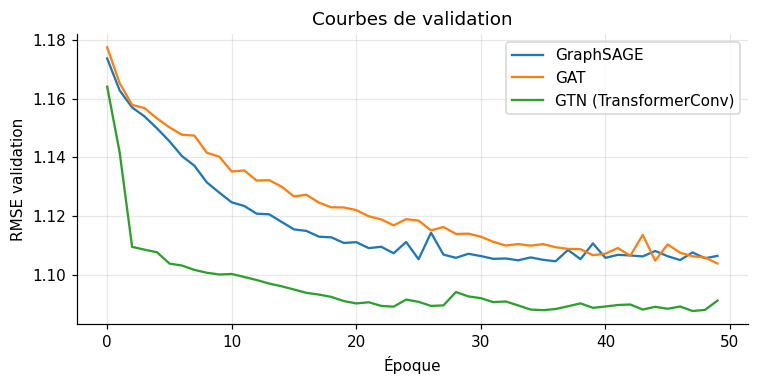

In [27]:
if RUN_GNN and HAS_TORCH:
    def train_model(kind, epochs=50, steps=3, lr=2e-3):
        torch.manual_seed(SEED); model = RatingNet(kind, D_in).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        best, best_state, hist = 1e9, None, []
        for ep in range(epochs):
            model.train()
            for _ in range(steps):
                perm = tr_ids[torch.randperm(len(tr_ids), device=device)]
                n_sup = int(0.2 * len(perm)); sup, msg = perm[:n_sup], perm[n_sup:]
                X, ei, ea = build_graph(msg)
                pred = MU_T + SD_T * model.decode(model.encode(X, ei, ea), U_t[sup], P_t[sup])
                loss = F.mse_loss(pred, Y_t[sup]); opt.zero_grad(); loss.backward(); opt.step()
            vr = float(np.sqrt(np.mean((evaluate(model, tr_ids, val_ids) - y_all_np[val_ids.cpu().numpy()]) ** 2))); hist.append(vr)
            if vr < best: best, best_state = vr, copy.deepcopy(model.state_dict())
            if (ep + 1) % 10 == 0: print(f'  [{kind}] époque {ep+1:>2}/{epochs} | perte train {loss.item():.3f} | RMSE val {vr:.4f} (meilleur {best:.4f})')
        model.load_state_dict(best_state); return model, hist

    models, hists = {}, {}
    for kind, name in [('sage', 'GraphSAGE'), ('gat', 'GAT'), ('gtn', 'GTN (TransformerConv)')]:
        t0 = time.time(); print(f'=== {name} ==='); models[name], hists[name] = train_model(kind); print(f'    durée : {time.time()-t0:.0f}s')
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for n, h in hists.items(): ax.plot(h, label=n)
    ax.set_xlabel('Époque'); ax.set_ylabel('RMSE validation'); ax.set_title('Courbes de validation'); ax.legend(); plt.tight_layout(); plt.show()

#### 🔎 Comment lire l'entraînement
- Le **RMSE de validation** doit descendre puis se stabiliser ; les poids retenus sont ceux du **minimum** (early stopping). Si la courbe remonte, c'est du **sur-apprentissage** (le modèle mémorise les arêtes train).
- **Perte train** (MSE sur les arêtes masquées) : elle sert de contrôle ; une grande distance avec le RMSE² de validation signale du sur-apprentissage.
- **Durées** : GraphSAGE (moyenne simple) est le plus rapide ; GAT et GTN coûtent plus cher car ils calculent des poids d'attention pour chaque arête — le **prix de l'expressivité** (cf. tableau Complexité du cours).
- Comparez la rapidité de convergence : les modèles à attention exploitent la **note de l'arête** (edge feature) dès la première couche.

### 6.5 Évaluation finale sur le jeu de test
Pour le test, le graphe de passage de messages utilise **toutes** les arêtes d'entraînement (train + val) ; les arêtes de test sont **invisibles**. On compare tout dans un tableau unique, avec en plus une métrique de **sentiment « par le graphe seul »** : on convertit la note prédite en classe (≤2.5 → négatif, ≤3.5 → neutre, sinon positif) et on calcule le **F1 macro** — c'est-à-dire : *peut-on deviner le sentiment d'un avis sans lire son texte, juste avec l'historique de l'utilisateur et du produit ?*

,RMSE,MAE,acc_arrondie,F1_sentiment_graphe
Moyenne globale,1.170,0.934,0.214,NaN
Biais (μ + b_u + b_p),1.078,0.830,0.370,0.370
GraphSAGE,1.102,0.846,0.375,0.367
GAT,1.101,0.843,0.381,0.356
GTN (TransformerConv),1.074,0.823,0.385,0.385


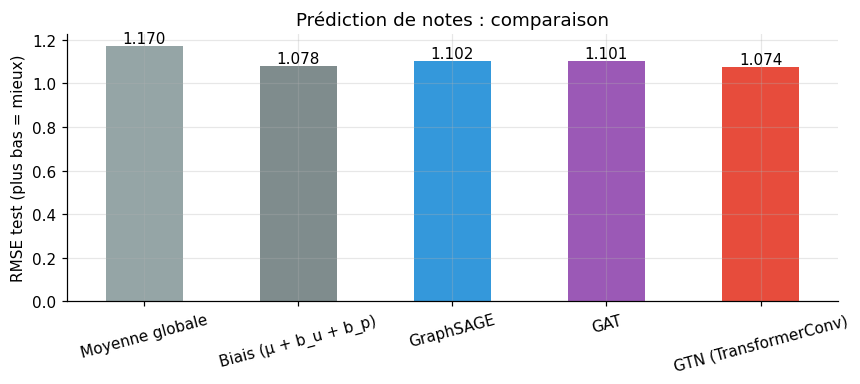

In [28]:
if RUN_GNN and HAS_TORCH:
    def to_class(r): return np.where(r < 2.5, 0, np.where(r < 3.5, 1, 2))
    for name, mdl in models.items():
        p = evaluate(mdl, train_all, test_ids); results_rate[name] = reg_metrics(y_te, p)
        results_rate[name]['F1_sentiment_graphe'] = float(f1_score(y_test, to_class(p), average='macro'))
    results_rate['Biais (μ + b_u + b_p)']['F1_sentiment_graphe'] = float(f1_score(y_test, to_class(np.clip(pred_bias, 1, 5)), average='macro'))
    rt = pd.DataFrame(results_rate).T.round(3); display(rt)
    fig, ax = plt.subplots(figsize=(8, 3.6)); rt['RMSE'].plot.bar(ax=ax, rot=15, color=['#95a5a6', '#7f8c8d', '#3498db', '#9b59b6', '#e74c3c'][:len(rt)])
    for i, v in enumerate(rt['RMSE']): ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')
    ax.set_ylabel('RMSE test (plus bas = mieux)'); ax.set_title('Prédiction de notes : comparaison'); plt.tight_layout(); plt.show()

#### 🔎 Comment lire le tableau
| Modèle | RMSE | MAE | Acc. arrondie | F1 sentiment (graphe seul) |
|---|---|---|---|---|
| Moyenne globale | 1,170 | 0,934 | 21,4 % | — |
| Biais (μ + b_u + b_p) | 1,078 | 0,830 | 37,0 % | 0,370 |
| GraphSAGE | 1,102 | 0,846 | 37,5 % | 0,367 |
| GAT | 1,101 | 0,843 | 38,1 % | 0,356 |
| **GTN (TransformerConv)** | **1,074** | **0,823** | **38,5 %** | **0,385** |

- **Le GTN est le meilleur modèle, mais l'écart est très faible** : RMSE 1,074 contre 1,078 pour la simple baseline de biais, soit −0,004 (≈ −0,4 %). Ce gain provient d'**un seul découpage et d'une seule graine** : il n'est pas établi statistiquement.
- **GraphSAGE (1,102) et GAT (1,101) font moins bien que la baseline de biais** : sur un graphe aussi creux, la moyenne ou l'attention scalaire des voisins n'apporte pas d'information au-delà des biais utilisateur/produit, et ajoute du bruit.
- **Ce que l'on peut dire honnêtement :** l'essentiel du signal est dans les **biais** (certains utilisateurs notent haut, certains produits sont meilleurs) ; le passage de messages n'ajoute presque rien ici. L'attention multi-têtes du GTN, qui exploite la **note de l'arête**, est la seule architecture à passer sous la baseline.
- **F1_sentiment_graphe** : F1 macro du sentiment deviné **sans lire le texte**, uniquement avec l'historique de l'utilisateur et du produit. Le GTN obtient **0,385**, au-dessus du hasard (≈ 0,33 pour 3 classes) mais très loin du texte (TF-IDF : 0,709) : les **deux vues sont complémentaires** (idée de fusion du cours, « données hybrides »).
- Annoncez ce que vous mesurez, sans sur-vendre le GTN. Pour consolider : plusieurs graines et un intervalle de confiance.


### 6.6 Explicabilité du GTN : que regarde l'attention ?
Le cours souligne que les Transformers sont **plus interprétables** car on peut visualiser les poids d'attention. Ici, la **première couche** du GTN nous donne, pour chaque arête, un poids d'attention (moyenné sur les 4 têtes). Pour un **produit** donné, on liste les utilisateurs auxquels il « prête le plus attention » et on vérifie si ces utilisateurs ont donné des **notes polarisées** (1–2 ou 5) — signe que l'attention capte les avis les plus informatifs.

Statistique globale : attention moyenne reçue selon la note de l'arête.

In [29]:
if RUN_GNN and HAS_TORCH:
    gtn = models['GTN (TransformerConv)'].eval()
    with torch.no_grad():
        X, ei, ea = build_graph(train_all)
        _, (ei_a, alpha) = gtn.c1(X, ei, ea, return_attention_weights=True)
    alpha = alpha.mean(1).cpu().numpy(); src, dst = ei_a[0].cpu().numpy(), ei_a[1].cpu().numpy()
    rating_of_edge = ((ea.squeeze(1).cpu().numpy() * 2) + 3).round().astype(int)
    att = pd.DataFrame(dict(src=src, dst=dst, alpha=alpha, note=rating_of_edge))
    att = att[att.dst >= n_users]                       # arêtes utilisateur → produit
    print('Attention moyenne selon la note de l\'arête :'); print(att.groupby('note').alpha.agg(['mean', 'count']).round(4))
    pid_star = int(att.dst.value_counts().index[0]); sub = att[att.dst == pid_star].sort_values('alpha', ascending=False).head(8)
    print(f'\nProduit le plus connecté : {prod_ids[pid_star - n_users]} ({int((att.dst == pid_star).sum())} avis dans le train)')
    print(sub.assign(utilisateur=[user_ids[s][:10] for s in sub.src])[['utilisateur', 'note', 'alpha']].round(4).to_string(index=False))

Attention moyenne selon la note de l'arête :
        mean  count
note               
1     0.1598   3323
2     0.1173   3800
3     0.0951   7468
4     0.1018  13558
5     0.1496  35285

Produit le plus connecté : B006MONQMC (384 avis dans le train)
utilisateur  note  alpha
 A2OW1FKQFP     1 0.0040
 A1A1BM6N28     1 0.0039
 AY46DEOJJY     1 0.0039
 A1WKEAS582     2 0.0038
 A3U029B8Z5     1 0.0038
 A3GSTWRM0D     2 0.0038
 A20MMOYFA8     1 0.0038
 AZFHSPEZUP     1 0.0037


#### 🔎 Comment lire la sortie
- **Attention moyenne selon la note de l'arête** : les avis **polarisés** reçoivent nettement plus d'attention que les avis intermédiaires — **1★ : 0,160 ; 5★ : 0,150** contre **3★ : 0,095 et 4★ : 0,102**. L'attention suit une courbe en « U » : le GTN a appris que les avis extrêmes sont les plus **informatifs** sur un produit. À nuancer : la note est fournie au modèle comme *edge feature*, donc l'attention peut la lire directement (ce n'est pas une structure découverte seule).
- **Produit le plus connecté (B006MONQMC, 384 avis dans le train)** : les 8 voisins qui reçoivent le plus d'attention ont tous donné **1★ ou 2★** (poids ≈ 0,0037–0,0040, soit ≈ 1,5 fois le poids uniforme 1/384 ≈ 0,0026). Le modèle s'appuie surtout sur les avis négatifs pour représenter ce produit.
- C'est l'**explicabilité** annoncée dans le cours (*« on peut visualiser les poids d'attention »*) : contrairement à GraphSAGE (moyenne aveugle), on sait **quels voisins ont pesé** dans la représentation du produit.


### 6.7 Les embeddings GNN retrouvent-ils les communautés ?
Dernier contrôle de cohérence : on clusterise par K-Means les **embeddings des utilisateurs** produits par le GTN (sortie de l'encodeur) et on mesure la **NMI** avec les communautés de Louvain (utilisateurs appartenant aux grandes communautés). Une NMI nettement > 0 montre que le GTN a **appris la structure de communauté** sans qu'on la lui donne.

In [30]:
if RUN_GNN and HAS_TORCH:
    from sklearn.cluster import KMeans
    with torch.no_grad():
        Hn = gtn.encode(*build_graph(train_all))[:n_users].cpu().numpy()
    uc = core.drop_duplicates('uid').set_index('uid').u_comm.reindex(range(n_users))
    ok = uc.isin(big).values
    k_big = len(big)
    lab = KMeans(k_big, n_init=5, random_state=SEED).fit_predict(Hn[ok])
    print(f'NMI(K-Means sur embeddings GTN, communautés Louvain) = {nmi(uc[ok].values, lab):.3f}  (k = {k_big})')

NMI(K-Means sur embeddings GTN, communautés Louvain) = 0.136  (k = 12)


#### 🔎 Comment lire la sortie
**NMI = 0,136 (k = 12)** : supérieure à 0, mais **loin de 1** → les embeddings du GTN retrouvent **en partie** les communautés de Louvain, alors que le GTN n'a jamais vu ces communautés (il n'a été entraîné qu'à prédire des notes). C'est un **accord partiel** : les deux méthodes captent des facettes proches mais différentes de la structure du graphe (le GTN s'appuie sur les notes et le texte, Louvain sur les seuls avis positifs). À comparer avec la NMI entre communautés et clusters de texte (0,100, section 5.2).


## 7. Système de recommandation

### 7.1 Protocole d'évaluation (top-N)
On cache les **avis positifs du jeu de test** (note ≥ 4) et on demande à chaque méthode de classer **tous les produits non encore achetés** par l'utilisateur ; on regarde si les produits cachés remontent dans le **top-10**.

Métriques (moyennées sur 3 000 utilisateurs de test) :
- **Hit@10** : au moins un produit caché dans le top-10 ;
- **Recall@10** : fraction des produits cachés retrouvés ;
- **NDCG@10** : récompense les bonnes réponses **placées haut** dans la liste ;
- **Couverture** : nombre de produits différents recommandés (mesure la diversité ; une méthode qui recommande toujours les mêmes best-sellers a une couverture faible).

⚠️ **Avertissement sur la difficulté :** avec ~8 000 produits candidats et ~3–4 avis par utilisateur, c'est une tâche **très dure** : des valeurs absolues de quelques % sont normales (le hasard donnerait ~0.1 %). Ce qui compte, c'est la **comparaison relative** entre méthodes.

### 7.2 Les cinq méthodes comparées
1. **Popularité** : produits les plus souvent bien notés (baseline classique, difficile à battre).
2. **Content-based (embeddings)** : profil utilisateur = moyenne des embeddings de ses avis positifs ; produit = moyenne des embeddings de ses avis ; score = **similarité cosinus**.
3. **Item-kNN (filtrage collaboratif)** : « ceux qui ont aimé A ont aussi aimé B » via la similarité cosinus entre colonnes de la matrice user×produit.
4. **Popularité dans la communauté** : best-sellers *dans la communauté Louvain de l'utilisateur* (**approche graphe**). Les communautés sont ici recalculées **sur les seules arêtes train** pour éviter toute fuite.
5. **Hybride** : combinaison pondérée (0.5 kNN + 0.3 content + 0.2 communauté) de scores normalisés par utilisateur.

In [31]:
from sklearn.preprocessing import normalize
tr_df, te_df = core.iloc[train_idx], core.iloc[test_idx]
pos_tr = tr_df[tr_df.Score >= 4]
R_pos = sp.csr_matrix((np.ones(len(pos_tr), dtype='float32'), (pos_tr.uid.values, pos_tr.pid.values)), shape=(n_users, n_prods))
R_seen = sp.csr_matrix((np.ones(len(tr_df), dtype='float32'), (tr_df.uid.values, tr_df.pid.values)), shape=(n_users, n_prods))

# ---- (1) popularité
pop = np.asarray(R_pos.sum(0)).ravel()
# ---- (2) content-based
Pvec = np.zeros((n_prods, emb.shape[1]), dtype='float32'); np.add.at(Pvec, pos_tr.pid.values, emb[pos_tr.index.values]); Pvec = normalize(Pvec)
Uvec = np.zeros((n_users, emb.shape[1]), dtype='float32'); np.add.at(Uvec, pos_tr.uid.values, emb[pos_tr.index.values]); Uvec = normalize(Uvec)
# ---- (3) item-kNN : cosinus entre colonnes de R_pos
Rn = normalize(R_pos, axis=0).tocsc().astype('float32'); S = (Rn.T @ Rn).tocsr(); S.setdiag(0); S.eliminate_zeros()
# ---- (4) communautés recalculées sur le TRAIN uniquement
Gtr = nx.Graph(); Gtr.add_weighted_edges_from(zip('U:' + pos_tr.UserId, 'P:' + pos_tr.ProductId, pos_tr.Score / 5.0))
comms_tr = nx.community.louvain_communities(Gtr, weight='weight', seed=SEED)
u_c = np.full(n_users, -1); p_c = np.full(n_prods, -1)
for i, c in enumerate(comms_tr):
    for n in c:
        (u_c.__setitem__ if n[0] == 'U' else p_c.__setitem__)(user_ids.get_loc(n[2:]) if n[0] == 'U' else prod_ids.get_loc(n[2:]), i)
print(f'Communautés (train seul) : {len(comms_tr)} | k-NN : {S.nnz:,} similarités non nulles')
comm_pop = {c: np.where(p_c == c, pop, 0.0) for c in set(p_c[p_c >= 0])}

# ---- ensemble d'évaluation
pos_te = te_df[te_df.Score >= 4]
held = pos_te.groupby('uid').pid.apply(set)
rng = np.random.RandomState(SEED); eval_users = rng.choice(held.index.values, size=min(3000, len(held)), replace=False)
print(f'Utilisateurs évalués : {len(eval_users):,} | produits cachés par utilisateur (moy.) : {np.mean([len(held[u]) for u in eval_users]):.2f}')

Communautés (train seul) : 92 | k-NN : 325,084 similarités non nulles
Utilisateurs évalués : 3,000 | produits cachés par utilisateur (moy.) : 1.78


Évaluation terminée en 10s


,Hit@10,Recall@10,NDCG@10,Couverture
Popularité,0.0773,0.0427,0.0249,21.0
Content (embeddings),0.0727,0.0543,0.0312,4963.0
Item-kNN,0.1183,0.0772,0.0526,6383.0
Communauté (graphe),0.0990,0.0613,0.0361,510.0
Hybride,0.1460,0.0993,0.0661,6304.0


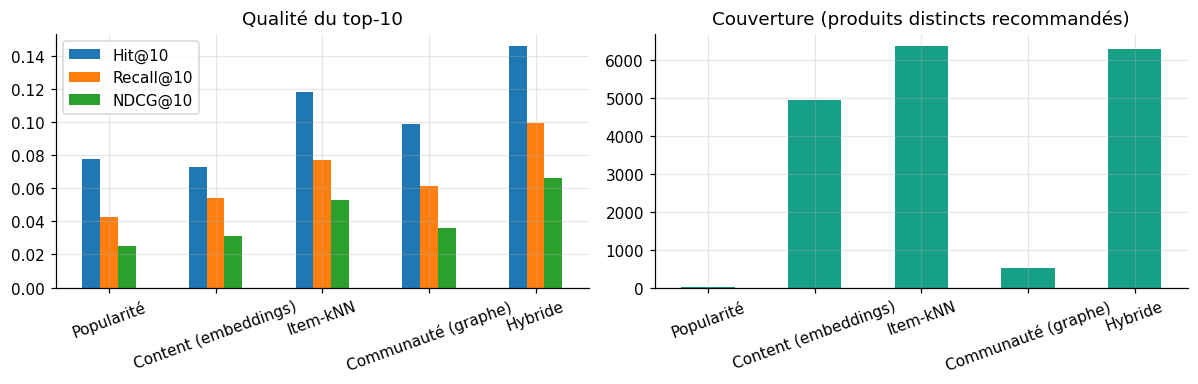

In [32]:
def minmax(a):
    lo, hi = a.min(), a.max(); return (a - lo) / (hi - lo + 1e-9)

def score_user(u, method):
    if method == 'Popularité': return pop.astype(float)
    if method == 'Content (embeddings)': return Pvec @ Uvec[u]
    if method == 'Item-kNN': return (R_pos[u] @ S).toarray().ravel()
    if method == 'Communauté (graphe)':
        c = u_c[u]; return comm_pop[c].copy() if c in comm_pop else pop.astype(float)
    if method == 'Hybride':
        return 0.5 * minmax(score_user(u, 'Item-kNN')) + 0.3 * minmax(score_user(u, 'Content (embeddings)')) + 0.2 * minmax(score_user(u, 'Communauté (graphe)'))

def evaluate_reco(method, K=10):
    hits, recs, ndcgs, shown = [], [], [], set()
    disc = 1.0 / np.log2(np.arange(2, K + 2))
    for u in eval_users:
        s = score_user(u, method).astype(float); s[R_seen[u].indices] = -1e9          # on exclut ce qui est déjà vu
        top = np.argpartition(-s, K)[:K]; top = top[np.argsort(-s[top])]; shown.update(top.tolist())
        truth = held[u]; rel = np.array([t in truth for t in top])
        hits.append(rel.any()); recs.append(rel.sum() / len(truth))
        ndcgs.append((rel * disc).sum() / disc[:min(len(truth), K)].sum())
    return dict(**{'Hit@10': np.mean(hits), 'Recall@10': np.mean(recs), 'NDCG@10': np.mean(ndcgs)}, Couverture=len(shown))

METHODS = ['Popularité', 'Content (embeddings)', 'Item-kNN', 'Communauté (graphe)', 'Hybride']
t0 = time.time(); reco_res = pd.DataFrame({m: evaluate_reco(m) for m in METHODS}).T
print(f'Évaluation terminée en {time.time()-t0:.0f}s'); display(reco_res.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
reco_res[['Hit@10', 'Recall@10', 'NDCG@10']].plot.bar(ax=ax[0], rot=20); ax[0].set_title('Qualité du top-10')
reco_res['Couverture'].plot.bar(ax=ax[1], rot=20, color='#16a085'); ax[1].set_title('Couverture (produits distincts recommandés)'); plt.tight_layout(); plt.show()

#### 🔎 Lecture des résultats (3 000 utilisateurs, ≈1,8 produit caché chacun)
| Méthode | Hit@10 | Recall@10 | NDCG@10 | Couverture |
|---|---|---|---|---|
| Popularité | 0,077 | 0,043 | 0,025 | 21 |
| Content (embeddings) | 0,073 | 0,054 | 0,031 | 4 963 |
| Item-kNN | 0,118 | 0,077 | 0,053 | 6 383 |
| Communauté (graphe) | 0,099 | 0,061 | 0,036 | 510 |
| **Hybride** | **0,146** | **0,099** | **0,066** | 6 304 |

- Le hasard donnerait un Hit@10 ≈ **0,2 %** : toutes les méthodes sont **des dizaines de fois meilleures**.
- **Popularité** : bon score pour une méthode non personnalisée, mais **seulement 21 produits distincts** recommandés à 3 000 personnes → aucune personnalisation, aucune découverte.
- **Communauté (graphe)** : mieux que la popularité simple (Hit@10 **+28 %**, couverture ×24) rien qu'en restreignant les best-sellers à la **communauté** de l'utilisateur → **la structure du graphe apporte de la personnalisation**.
- **Item-kNN (filtrage collaboratif)** : **+53 %** de Hit@10 sur la popularité ; la corrélation des achats est un signal puissant.
- **Content (embeddings MiniLM)** : son Hit@10 (0,073) reste **légèrement sous la popularité** (0,077), mais son Recall@10 (0,054) et son NDCG@10 (0,031) la dépassent (≈ +27 % et +25 %), avec une couverture de 4 963 produits : il personnalise, mais ne suffit pas seul.
- **Hybride** : meilleur sur toutes les métriques de précision (**Hit@10 ×1,9 et NDCG ×2,7 par rapport à la popularité** ; +23 % de Hit@10 et +26 % de NDCG par rapport au meilleur modèle simple, Item-kNN) : les signaux **collaboratif + texte + communauté** sont **complémentaires** — c'est le message principal de la section.
- Couverture élevée de l'hybride (6 304 produits recommandés) = recommandations **diversifiées**, pas centrées sur les best-sellers.


### 7.3 Exemple concret de recommandation
Le dataset ne contient **pas les noms des produits** (seulement `ProductId`). Pour rendre les recommandations lisibles, on décrit chaque produit par ses **mots-clés TF-IDF** et sa **note moyenne**. On choisit un utilisateur de test, on affiche **ce qu'il a aimé** puis le **top-5 de la méthode hybride**, et on indique si l'un d'eux faisait partie des avis cachés (✅).

In [33]:
def product_card(p, n_terms=6):
    mask = (core.pid.values == p)
    m = np.asarray(T_all[np.where(mask)[0]].mean(axis=0)).ravel()
    return f"{prod_ids[p]} | note {core.Score.values[mask].mean():.2f} ({mask.sum()} avis) | " + ', '.join(tf_vocab[np.argsort(m)[::-1][:n_terms]])

u_demo = next(u for u in eval_users if len(held[u]) >= 1 and R_pos[u].nnz >= 3)
print('👤 Utilisateur', user_ids[u_demo], '— produits qu\'il a aimés (train) :')
for p in R_pos[u_demo].indices[:4]: print('   •', product_card(p))
s = score_user(u_demo, 'Hybride').astype(float); s[R_seen[u_demo].indices] = -1e9
print('\n🎯 Top-5 recommandés (hybride) :')
for p in np.argsort(-s)[:5]: print('   ' + ('✅' if p in held[u_demo] else '•'), product_card(p))

👤 Utilisateur A3LGT6UZL99IW1 — produits qu'il a aimés (train) :
   • B0041NYV8E | note 3.13 (437 avis) | ginger, lemon, drink, hot, strong, beverage
   • B007I7Z3Z0 | note 3.77 (274 avis) | tea, honey, water, lipton, drink, green
   • B002RSVOLM | note 3.36 (44 avis) | celsius, acai, drink, raspberry, energy, caffeine
   • B000G2UUOS | note 4.22 (27 avis) | snack, protein, soy, crunchy, great, healthy

🎯 Top-5 recommandés (hybride) :
   ✅ B002IEZJMA | note 3.59 (463 avis) | coffee, drink, illy, espresso, issimo, strong
   • B004E4CCSQ | note 3.47 (249 avis) | peach, mio, water, tea, flavor, bottle
   • B004E4EBMG | note 3.73 (244 avis) | mio, peach, water, mango, flavor, bottle
   • B004JGQ15E | note 4.23 (274 avis) | popcorn, caramel, snack, fudge, snackwell, drizzle
   • B0090X8IPM | note 3.83 (459 avis) | vanilla, coffee, starbucks, flavored, coffees, flavor


#### 🔎 Lecture de l'exemple
L'utilisateur avait aimé une **boisson gingembre-citron, un thé vert au miel, une boisson énergisante à l'açaï et un snack protéiné** (profil « boissons & santé »). Le top-5 hybride propose un **café Illy**, deux **eaux aromatisées Mio** (pêche, mangue), un **pop-corn au caramel** et un **café vanille Starbucks** : cohérent avec ses goûts de boissons et de snacks. Le ✅ marque le **café Illy**, qu'il a effectivement aimé plus tard (avis caché du test) : la recommandation est **correcte et vérifiée**.
Limites visibles : **une seule** des cinq recommandations est vérifiée par le test, et plusieurs produits recommandés ont une note moyenne modeste (3,47 à 3,83 pour quatre d'entre eux) : le score hybride ne filtre pas sur la qualité. Une étiquette de catégorie ou un seuil de note améliorerait la pertinence.


## 8. Graph-RAG : questions/réponses sur le graphe (Chapitre 4)

### 8.1 Principe (cours *Architecture RAG* et *Graph RAG vs RAG*)
Le **RAG** combine **recherche** (retriever) et **génération** ; le **Graph-RAG** ajoute un **graphe de connaissances** pour *raisonner* sur les relations (voisinage, propagation) au lieu de ne récupérer que des passages « similaires ».

**Notre pipeline :**
1. **Base de connaissances** = les avis (texte + embeddings) **et** le graphe (utilisateurs, produits, thèmes, communautés).
2. **Retriever sémantique** : la question est encodée par le même modèle (MiniLM) → on récupère les **avis les plus proches** (similarité cosinus).
3. **Expansion par le graphe** : les avis pointent vers des **produits** ; on agrège avec le graphe (note moyenne, nombre d'avis, thème, communauté).
4. **Classement** des produits par **note moyenne bayésienne** `(C·m + Σnotes) / (C + n)` : un produit à 5.0 sur **2 avis** ne doit pas battre un produit à 4.8 sur 300 (m = moyenne globale, C = 10 « avis fictifs »).
5. **Génération** de la réponse : gabarit de texte avec **preuves citées** (extraits d'avis) ; option **Flan-T5** (`RUN_LLM`) pour reformuler.

Deux types de questions de l'énoncé : *« quels produits sont les mieux notés pour tel type d'aliment ? »* et *« quels utilisateurs ont des goûts similaires ? »* (traversée de graphe *utilisateur → produit → utilisateur*).

### 8.2 Construction du graphe de connaissances et du retriever
On enrichit le graphe avec des nœuds **Thème** (K-Means sur les embeddings **produits**, K = 12, mots-clés TF-IDF) et **Communauté** (Louvain), reliés par `IN_TOPIC` / `IN_COMMUNITY`.

In [34]:
# ---------- statistiques produits (bayésiennes) ----------
m_glob, C_PRIOR = core.Score.mean(), 10
pstats = core.groupby('pid').agg(n=('Score', 'size'), mean=('Score', 'mean'), s=('Score', 'sum'))
pstats['bayes'] = (C_PRIOR * m_glob + pstats.s) / (C_PRIOR + pstats.n)

# ---------- thèmes de produits (K-Means sur embeddings moyens des produits) ----------
Pmean = np.zeros((n_prods, emb.shape[1]), dtype='float32'); np.add.at(Pmean, core.pid.values, emb); Pmean = normalize(Pmean)
km_p = MiniBatchKMeans(n_clusters=12, random_state=SEED, n_init=5, batch_size=2048).fit(Pmean); prod_topic = km_p.labels_
topic_kw = {}
for t in range(12):
    rows = np.where(np.isin(core.pid.values, np.where(prod_topic == t)[0]))[0]
    topic_kw[t] = ', '.join(tf_vocab[np.argsort(np.asarray(T_all[rows].mean(0)).ravel())[::-1][:5]])

# ---------- graphe de connaissances hétérogène ----------
KG = nx.MultiDiGraph()
for p in range(n_prods):
    KG.add_node('P:' + prod_ids[p], type='Product', n=int(pstats.n.get(p, 0)), bayes=float(pstats.bayes.get(p, m_glob)), topic=int(prod_topic[p]))
KG.add_nodes_from(users_nodes, type='User')
KG.add_edges_from([(u, p, dict(rel='REVIEWED', score=int(s))) for u, p, s in zip('U:' + core.UserId, 'P:' + core.ProductId, core.Score)])
for t in range(12): KG.add_node(f'T:{t}', type='Topic', keywords=topic_kw[t])
for p in range(n_prods): KG.add_edge('P:' + prod_ids[p], f'T:{prod_topic[p]}', rel='IN_TOPIC')
for i, c in enumerate(comms):
    KG.add_node(f'C:{i}', type='Community', size=len(c))
    for n in c:
        if n in KG: KG.add_edge(n, f'C:{i}', rel='IN_COMMUNITY')
types = collections.Counter(d['type'] for _, d in KG.nodes(data=True)); rels = collections.Counter(d['rel'] for _, _, d in KG.edges(data=True))
print('Nœuds par type :', dict(types)); print('Arêtes par relation :', dict(rels))
print('\nThèmes de produits découverts :'); [print(f'  T{t} ({int((prod_topic==t).sum())} produits) : {topic_kw[t]}') for t in range(12)]

Nœuds par type : {'Product': 8372, 'User': 13118, 'Topic': 12, 'Community': 34}
Arêtes par relation : {'IN_TOPIC': 8372, 'IN_COMMUNITY': 21196, 'REVIEWED': 79293}

Thèmes de produits découverts :
  T0 (464 produits) : drink, water, hair, like, taste
  T1 (614 produits) : great, good, beans, butter, nuts
  T2 (1219 produits) : sauce, good, great, oil, like
  T3 (704 produits) : coffee, cup, flavor, good, like
  T4 (1588 produits) : snack, good, cookies, like, taste
  T5 (214 produits) : tea, green, drink, flavor, taste
  T6 (850 produits) : chocolate, sugar, milk, taste, good
  T7 (690 produits) : pasta, soup, noodles, good, sauce
  T8 (766 produits) : cereal, gluten, good, free, great
  T9 (446 produits) : dog, dogs, treats, food, loves
  T10 (505 produits) : tea, teas, flavor, drink, ginger
  T11 (312 produits) : cats, cat, food, eat, love


[None, None, None, None, None, None, None, None, None, None, None, None]

#### 🔎 Lecture du résultat
Le graphe de connaissances hétérogène contient **4 types de nœuds** : 13 118 *User*, 8 372 *Product*, 12 *Topic*, 34 *Community* ; et **3 types de relations** : `REVIEWED` (79 293, pondérée par la note), `IN_TOPIC` (8 372) et `IN_COMMUNITY` (21 196 — seuls les nœuds ayant ≥ 1 avis positif ont une communauté). C'est la structure du cours : *nœuds (entités) + arêtes (relations sémantiques)*.

**Thèmes de produits** (K-Means sur les embeddings produits) : T0 boissons/eau (et soin « hair ») · T1 beurres et noix · T2 sauces/huiles · T3 café/dosettes · T4 snacks/biscuits (1 588 produits, le plus gros) · T5 thé vert · T6 chocolat/sucre/lait · T7 pâtes/soupes/nouilles · T8 céréales/sans gluten · T9 chiens · T10 thés/infusions · T11 chats. **Limites** : T0 mélange des boissons et quelques produits de soin ; T5 et T10 sont deux thèmes « thé » proches ; T4 est large et assez générique.


In [35]:
# ---------- le retriever sémantique ----------
if 'st_model' not in globals() and emb.shape[1] == 384:      # embeddings MiniLM rechargés depuis le cache → on recharge le modèle
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', device=device); st_model.max_seq_length = 128
if 'st_model' in globals():
    encode_q = lambda q: st_model.encode([q], normalize_embeddings=True)[0]
else:   # repli sans sentence-transformers : on reconstruit la projection TF-IDF + SVD pour encoder les requêtes
    from sklearn.decomposition import TruncatedSVD
    _tf = TfidfVectorizer(max_features=40000, min_df=3, stop_words='english', sublinear_tf=True).fit(core.full_text)
    _svd = TruncatedSVD(emb.shape[1], random_state=SEED).fit(_tf.transform(core.full_text))
    encode_q = lambda q: normalize(_svd.transform(_tf.transform([q])))[0]
lower_text = core.full_text.str.lower().values

def retrieve(query, k=300):
    sims = emb @ encode_q(query).astype('float32'); top = np.argpartition(-sims, k)[:k]; return top[np.argsort(-sims[top])], sims

def best_products(query, k=5, k_reviews=300, min_reviews=5):
    # Retrieval -> agrégation par produit -> classement bayésien
    top, sims = retrieve(query, k_reviews); hit = collections.Counter(core.pid.values[top])
    cand = [(p, h) for p, h in hit.items() if pstats.n[p] >= min_reviews and h >= 2]
    cand.sort(key=lambda x: (-pstats.bayes[x[0]], -x[1])); out = []
    for p, h in cand[:k]:
        best_rev = max(top[core.pid.values[top] == p], key=lambda i: sims[i])
        out.append(dict(product=prod_ids[p], bayes=round(float(pstats.bayes[p]), 2), mean=round(float(pstats['mean'][p]), 2), n_reviews=int(pstats.n[p]),
                        hits=h, theme=topic_kw[prod_topic[p]], evidence=core.full_text.values[best_rev][:170]))
    return out

def similar_users(user_id, k=5):
    # Traversée de graphe : utilisateur -> produits aimés -> autres utilisateurs ; score = Jaccard sur les produits aimés
    u = 'U:' + user_id; liked = {p for p in Gpos.neighbors(u)} if u in Gpos else set()
    votes = collections.Counter(v for p in liked for v in Gpos.neighbors(p) if v != u)
    scored = sorted(((v, c / (len(liked) + Gpos.degree(v) - c)) for v, c in votes.items()), key=lambda x: -x[1])[:k]
    return [dict(user=v[2:], jaccard=round(j, 3), produits_communs=len(liked & set(Gpos.neighbors(v))), meme_communaute=node_comm.get(v) == node_comm.get(u)) for v, j in scored], liked

def answer_best(query, k=3):
    res = best_products(query, k)
    if not res: return f"Aucun produit fiable trouvé pour « {query} »."
    lines = [f"Pour « {query} », voici les produits les mieux notés (note bayésienne) :"]
    for r in res: lines.append(f"  • {r['product']} — {r['bayes']}/5 sur {r['n_reviews']} avis (thème : {r['theme'].split(',')[0]}). Extrait : « {r['evidence']}… »")
    return '\n'.join(lines)
print('Retriever prêt. Exemple de test de la fonction answer_best :'); print(answer_best('best coffee beans', 3))

Retriever prêt. Exemple de test de la fonction answer_best :
Pour « best coffee beans », voici les produits les mieux notés (note bayésienne) :
  • B000FIAWVE — 4.59/5 sur 13 avis (thème : great). Extrait : « Best Beans Ever!!!. I eat all kinds of beans as they are a main source of my protein intake. These rank up there as one of my top three favorite. Fast and easy to make an… »
  • B000KSTYBS — 4.57/5 sur 19 avis (thème : coffee). Extrait : « great tasting coffee. I bought a couple of bags of French roast beans and I love it!I grind my own very fine because I love a full bodied cup of coffee.In fact, I decided… »
  • B001SJR4XS — 4.5/5 sur 13 avis (thème : coffee). Extrait : « Now THIS is some serious coffee !!. Very impressed coffee junkie here. What coffee should be, but seldom is. Beautiful, dark oily beans with a grand aroma. Roasted perfec… »


### 8.3 Démonstration : questions-types de l'énoncé
**Q1 — produits les mieux notés par type d'aliment** (trois requêtes). **Q2 — utilisateurs aux goûts similaires** pour un utilisateur actif.

In [36]:
for q in ['strong dark roast coffee', 'gluten free snacks', 'healthy dog food for sensitive stomach']:
    print(answer_best(q, 3)); print('-' * 100)

active_user = core.UserId.value_counts().index[5]
sim, liked = similar_users(active_user, 5)
print(f'\n👥 Utilisateurs aux goûts proches de {active_user} ({len(liked)} produits aimés) :')
print(pd.DataFrame(sim).to_string(index=False))

Pour « strong dark roast coffee », voici les produits les mieux notés (note bayésienne) :
  • B000KSTYBS — 4.57/5 sur 19 avis (thème : coffee). Extrait : « Good all around coffee. Very good taste, not bitter. I like a rich dark strong cup of coffee in the morning and this suits the bill. I am also going to try more of their … »
  • B0032BXUJM — 4.56/5 sur 23 avis (thème : coffee). Extrait : « Great Coffee. This coffee is bold and strong, just how I like it. If you don't like bold/strong coffee, this is not for you.… »
  • B001HKZZ4I — 4.53/5 sur 8 avis (thème : coffee). Extrait : « Delicious Light Roast!. This light roast is absolutely delicious. I normally buy dark roasts, but my husband wanted me to get some lighter roast K-Cups for him. I was was… »
----------------------------------------------------------------------------------------------------
Pour « gluten free snacks », voici les produits les mieux notés (note bayésienne) :
  • B001CWV4RS — 4.8/5 sur 48 avis (thème : snack). 

#### 🔎 Lecture des réponses
**Q1 — meilleurs produits par type d'aliment** :
- *« strong dark roast coffee »* → trois **cafés** notés **4,53–4,57** (8 à 23 avis), avec un extrait pertinent à l'appui. Le système **récupère** par le sens, **agrège** par produit et **classe** par note bayésienne : exactement le pipeline RAG. **Limite visible :** le 3ᵉ résultat est un café en **torréfaction légère** (« Delicious Light Roast », seulement 8 avis) alors que la requête demande un café *dark roast* : la recherche par le sens rapproche « café » et « torréfaction » sans toujours respecter l'adjectif.
- *« gluten free snacks »* → produits à **4,69–4,80/5** (20 à 48 avis), notes plus fiables car portées par davantage d'avis (dont des bretzels et de l'avoine sans gluten).
- *« healthy dog food for sensitive stomach »* → notes de **4,40 à 4,55** mais sur **5 à 11 avis seulement** : le seuil `min_reviews=5` laisse passer des produits peu documentés, et le 3ᵉ résultat est une friandise (*treat*) pour chien plutôt qu'un aliment. À durcir en production, par exemple avec un **filtre sur le thème du graphe** (T9 « chiens ») et un seuil d'avis plus élevé.

**Q2 — utilisateurs aux goûts proches** : pour un utilisateur avec 70 produits aimés, les voisins ont une similarité de **Jaccard ≈ 0,05–0,06** (4 à 6 produits en commun). La valeur est faible mais **attendue** : sur un graphe aussi creux, deux utilisateurs très actifs ne partagent qu'une petite fraction de leurs achats. À noter : aucun de ces voisins n'est dans la **même communauté Louvain** — pour un utilisateur « touche-à-tout », les communautés (qui regroupent des niches) ne résument pas le profil ; la traversée de graphe est ici plus fine.


### 8.4 Évaluation du Graph-RAG
Le cours propose d'évaluer le **retriever** (precision@k) et le **générateur**. Sans annotations humaines, nous mesurons la **pureté thématique** : pour 10 requêtes d'aliments, on regarde, parmi les 10 produits renvoyés, la fraction dont **au moins 30 % des avis contiennent le mot-clé**. On la compare à une **baseline sans retrieval** (les 10 produits les mieux notés globalement) : si le retriever fonctionne, la pureté est élevée pour lui et proche de 0 pour la baseline.

In [37]:
test_queries = {'coffee': 'best coffee', 'tea': 'green tea', 'chocolate': 'dark chocolate', 'dog': 'dog treats', 'cat': 'cat food', 'peanut': 'peanut butter',
               'gluten': 'gluten free', 'baby': 'baby food', 'sauce': 'hot sauce', 'oil': 'olive oil'}
pid_arr = core.pid.values
def purity(pids, kw):
    return np.mean([np.mean([kw in t for t in lower_text[pid_arr == p]]) >= 0.30 for p in pids]) if len(pids) else 0.0
global_top = list(pstats[pstats.n >= 5].sort_values('bayes', ascending=False).index[:10])
rows = []
for kw, q in test_queries.items():
    got = [prod_ids.get_loc(r['product']) for r in best_products(q, 10)]
    rows.append(dict(requête=q, produits_renvoyés=len(got), pureté_RAG=purity(got, kw), pureté_baseline=purity(global_top, kw)))
ev = pd.DataFrame(rows); display(ev.round(2)); print(f"\nPureté moyenne — Graph-RAG : {ev.pureté_RAG.mean():.2f} | baseline sans retrieval : {ev.pureté_baseline.mean():.2f}")

,requête,produits_renvoyés,pureté_RAG,pureté_baseline
0,best coffee,10,1.0,0.0
1,green tea,10,1.0,0.0
2,dark chocolate,10,1.0,0.0
3,dog treats,10,1.0,0.0
4,cat food,10,1.0,0.0
5,peanut butter,10,0.9,0.0
6,gluten free,10,1.0,0.3
7,baby food,10,1.0,0.0
8,hot sauce,10,1.0,0.0
9,olive oil,10,1.0,0.2



Pureté moyenne — Graph-RAG : 0.99 | baseline sans retrieval : 0.05


#### 🔎 Lecture du résultat
**Pureté moyenne : 0,99 pour le Graph-RAG contre 0,05 pour la baseline sans retrieval.** Sans recherche, les meilleurs produits globaux n'ont presque jamais rapport avec la requête (0,0 pour 8 requêtes sur 10, 0,2–0,3 pour « olive oil » et « gluten free ») ; avec le retriever, **9 requêtes sur 10 obtiennent 1,00** (café, thé, chocolat, chien, chat, sans gluten, bébé, sauce piquante, huile d'olive) et « peanut butter » obtient 0,90.
⚠️ **À nuancer à l'oral :** cette métrique est **indulgente** (un seul mot-clé, seuil de 30 % des avis) et ne mesure ni le **rappel** (a-t-on trouvé *tous* les bons produits ?) ni la **qualité de la réponse générée**. Les cas de la section 8.3 (café en torréfaction légère pour une requête « dark roast », friandise pour une requête « dog food ») montrent qu'un score quasi parfait n'exclut pas des erreurs. Pour une évaluation complète : *precision@k/recall@k* sur jugements humains et **RAGAS** (*faithfulness*, *answer relevance*), comme dans le cours *Évaluation du RAG*.


### 8.5 (Optionnel) Génération de réponse avec un LLM — Flan-T5
Dans l'architecture RAG complète, le **générateur** (un LLM) reçoit la question **et les passages récupérés** dans un *prompt* (Chapitre 4 : *prompt engineering* — instruction + contexte + question). Ici on utilise **`google/flan-t5-base`** (250 M paramètres, modèle encodeur-décodeur *Seq2Seq* vu au Chapitre 2) : il reformule les preuves en une réponse courte et **fondée sur le contexte fourni** (ce qui réduit les hallucinations).
Activez avec `RUN_LLM = True` (GPU conseillé).

In [38]:
if RUN_LLM and HAS_TORCH:
    from transformers import pipeline
    gen = pipeline('text2text-generation', model='google/flan-t5-base', device=0 if device == 'cuda' else -1)
    def answer_llm(query, k=3):
        res = best_products(query, k)
        ctx = '\n'.join(f"Product {r['product']} (score {r['bayes']}/5, {r['n_reviews']} reviews): {r['evidence']}" for r in res)
        prompt = f"Answer the question using ONLY the context.\nContext:\n{ctx}\nQuestion: Which products are best for '{query}' and why?\nAnswer:"
        return gen(prompt, max_new_tokens=100, do_sample=False)[0]['generated_text']
    print(answer_llm('strong dark roast coffee'))
else:
    print('Génération LLM ignorée (RUN_LLM=False) — les réponses ci-dessus utilisent le gabarit avec preuves.')

Génération LLM ignorée (RUN_LLM=False) — les réponses ci-dessus utilisent le gabarit avec preuves.


## 9. Sauvegarde des livrables
Export dans `outputs/` : table des produits (note bayésienne, thème, communauté), table des utilisateurs (communauté), résultats de comparaison (CSV), graphe (GEXF, déjà exporté) et embeddings. Un `zip` est créé pour un téléchargement facile.

In [39]:
prod_out = pd.DataFrame({'ProductId': prod_ids, 'n_reviews': pstats.n.reindex(range(n_prods)).fillna(0).astype(int).values,
                         'mean_score': pstats['mean'].reindex(range(n_prods)).round(3).values, 'bayes_score': pstats.bayes.reindex(range(n_prods)).round(3).values,
                         'topic': prod_topic, 'topic_keywords': [topic_kw[t] for t in prod_topic], 'community': [node_comm.get('P:' + p, -1) for p in prod_ids]})
user_out = pd.DataFrame({'UserId': user_ids, 'community': [node_comm.get('U:' + u, -1) for u in user_ids]})
prod_out.to_csv('outputs/products.csv', index=False); user_out.to_csv('outputs/users_communities.csv', index=False)
pd.DataFrame(results_sent).T.to_csv('outputs/results_sentiment.csv'); reco_res.to_csv('outputs/results_recommendation.csv')
if 'rt' in globals(): rt.to_csv('outputs/results_rating_prediction.csv')
comm_df.to_csv('outputs/communities_profile.csv', index=False); ev.to_csv('outputs/results_graph_rag.csv', index=False)
import shutil; shutil.make_archive('projet_outputs', 'zip', 'outputs')
print('Fichiers exportés :', sorted(os.listdir('outputs')))
try:
    from google.colab import files; files.download('projet_outputs.zip')
except Exception: pass

Fichiers exportés : ['communities_profile.csv', 'distilbert_sentiment', 'graph_user_product.gexf', 'products.csv', 'results_graph_rag.csv', 'results_rating_prediction.csv', 'results_recommendation.csv', 'results_sentiment.csv', 'review_embeddings.npy', 'users_communities.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Déploiement Streamlit (application web)

### 10.1 Objectif et architecture
Les livrables du projet doivent être **utilisables**, pas seulement exécutables dans un notebook. Nous déployons donc une **application web Streamlit** qui expose les quatre capacités demandées par l'énoncé :

| Page de l'application | Ce qu'elle fait | Section du notebook réutilisée |
|---|---|---|
| **Accueil** | chiffres clés, distribution des notes, tableaux de résultats | 1, 3, 6, 7 |
| **Sentiment** | classe un avis saisi (négatif / neutre / positif), affiche les probabilités et les mots décisifs ; option DistilBERT si le modèle fine-tuné est présent | 3 |
| **Recommandation** | top-N de produits pour un utilisateur (hybride, item-kNN, content, communauté, popularité) avec ses produits déjà aimés | 7 |
| **Questions/Réponses (Graph-RAG)** | « quels produits sont les mieux notés pour… ? » et « quels utilisateurs ont des goûts similaires ? » | 8 |
| **Communautés** | profil des communautés Louvain et produits les plus commentés de chacune | 5 |

**Principe de conception : séparer le calcul lourd de l'interface.** L'entraînement (embeddings, Louvain, modèles) est fait **une fois** dans ce notebook, puis sauvegardé dans `streamlit_app/app_data/` :
- `app_data.joblib` : avis (texte tronqué à 400 caractères), embeddings en float16, identifiants, communautés, thèmes, tables de résultats ;
- `sentiment_tfidf.joblib` : le modèle TF-IDF + régression logistique entraîné en section 3.1 ;
- `distilbert_sentiment/` (optionnel) : le modèle fine-tuné de la section 3.4.

L'application ne recalcule au démarrage que des structures **légères** (matrices creuses, similarités item-item, voisinages), mises en cache avec `@st.cache_resource` : elle démarre en quelques secondes et chaque interaction est quasi instantanée. Le retriever du Q&A utilise MiniLM si `sentence-transformers` est installé, sinon un repli TF-IDF : l'application **ne plante donc jamais** faute d'une dépendance optionnelle.

### 10.2 Export des artefacts pour l'application
Cette cellule crée le dossier `streamlit_app/`, y sauvegarde les artefacts ci-dessus et le fichier `requirements.txt` (dépendances minimales pour un déploiement cloud).

In [40]:
import joblib
APP_DIR = 'streamlit_app'
os.makedirs(APP_DIR + '/app_data', exist_ok=True)

app_core = core[['UserId', 'ProductId', 'Score', 'label', 'uid', 'pid']].copy()
app_core['text'] = core.full_text.str.slice(0, 400)                  # texte tronqué : suffisant pour les extraits, 3x plus léger
joblib.dump(dict(core=app_core, emb=emb.astype('float16'), prod_ids=list(prod_ids), user_ids=list(user_ids),
                 node_comm=node_comm, prod_topic=prod_topic, topic_kw=topic_kw, comm_profile=comm_df,
                 results={'Sentiment (jeu de test)': pd.DataFrame(results_sent).T.round(3),
                          'Prédiction de notes (jeu de test)': pd.DataFrame(results_rate).T.round(3),
                          'Recommandation (top-10)': reco_res.round(4)}),
            APP_DIR + '/app_data/app_data.joblib', compress=3)
joblib.dump(dict(vec=tfidf, clf=clf_tfidf, labels=LABELS), APP_DIR + '/app_data/sentiment_tfidf.joblib', compress=3)
if os.path.isdir('outputs/distilbert_sentiment'):                         # modèle BERT fine-tuné (si l'étape 3.4 a été exécutée)
    shutil.copytree('outputs/distilbert_sentiment', APP_DIR + '/app_data/distilbert_sentiment', dirs_exist_ok=True)

with open(APP_DIR + '/requirements.txt', 'w') as f:
    f.write('streamlit>=1.32\npandas\nnumpy\nscipy\nscikit-learn\njoblib\n')   # minimal : le retriever bascule sur TF-IDF sans sentence-transformers
for fn in sorted(os.listdir(APP_DIR + '/app_data')):
    p = os.path.join(APP_DIR, 'app_data', fn); print(f'{fn:35s}', f'{(os.path.getsize(p) if os.path.isfile(p) else 0)/1e6:8.1f} Mo')

app_data.joblib                         68.7 Mo
distilbert_sentiment                     0.0 Mo
sentiment_tfidf.joblib                   2.1 Mo


#### 🔎 Lecture du résultat
Le dossier `streamlit_app/app_data/` contient deux fichiers essentiels :
- **`app_data.joblib`** : **68,7 Mo** (dont ≈ 61 Mo d'embeddings MiniLM : 79 293 × 384 × 2 octets en float16). C'est **sous la limite de 100 Mo** par fichier de GitHub, donc **Git LFS n'est pas nécessaire** (GitHub affiche seulement un avertissement au-delà de 50 Mo).
- **`sentiment_tfidf.joblib`** : **2,1 Mo** seulement (vocabulaire + coefficients du modèle TF-IDF).
Si l'étape DistilBERT a été exécutée, un sous-dossier `distilbert_sentiment/` (**≈ 268 Mo** : le fichier `model.safetensors`) est ajouté : il **dépasse la limite de 100 Mo de GitHub** et ne doit pas être poussé. Pour un déploiement cloud, supprimez-le (l'application bascule alors automatiquement sur TF-IDF) ou hébergez-le sur Hugging Face Hub.
La troncature du texte à 400 caractères divise par ~3 le poids du fichier sans gêner l'affichage d'extraits de 180 caractères.


### 10.3 Écriture du code de l'application (`app.py`)
Le code complet de l'application est écrit dans `streamlit_app/app.py`. Il se compose de **deux parties** volontairement séparées :

1. **La classe `Engine`** (aucune dépendance à l'interface, donc testable seule) : `predict_sentiment`, `recommend`, `best_products`, `similar_users`, `answer`. C'est la **même logique** que les sections 3, 7 et 8 du notebook (hybride 0,5 kNN + 0,3 content + 0,2 communauté, note bayésienne, similarité de Jaccard), ce qui garantit que l'application affiche exactement ce que le notebook a évalué.
2. **La fonction `main()`** : l'interface Streamlit (barre latérale de navigation, widgets, tableaux, graphiques).

Les décisions importantes du code : `@st.cache_resource` charge le moteur **une seule fois** par session serveur ; les produits déjà vus sont exclus des recommandations ; un utilisateur absent du graphe (filtré par le 3-core) reçoit un message clair au lieu d'une erreur ; la page de sentiment montre les **mots qui ont le plus pesé** dans la décision, ce qui rend le modèle explicable.

In [41]:
APP_CODE = r'''# -*- coding: utf-8 -*-
# Application Streamlit : Analyse et recommandation de produits a partir des avis clients
# Lancement :  streamlit run app.py
import os, re, collections
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import joblib
import streamlit as st
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer

HERE = Path(__file__).parent
DATA = HERE / 'app_data'
LABELS = ['négatif', 'neutre', 'positif']
METHODS = ['Hybride', 'Item-kNN', 'Content (embeddings)', 'Communauté (graphe)', 'Popularité']


# ------------------------------------------------------------------ moteur (logique sans interface)
def minmax(a):
    lo, hi = a.min(), a.max()
    return (a - lo) / (hi - lo + 1e-9)


class Engine:
    # Charge les artefacts du notebook et expose : sentiment, recommandation, Graph-RAG.
    def __init__(self, d, sent):
        self.core = d['core'].reset_index(drop=True)
        self.emb = d['emb'].astype('float32')
        self.prod_ids, self.user_ids = list(d['prod_ids']), list(d['user_ids'])
        self.pidx = {p: i for i, p in enumerate(self.prod_ids)}
        self.uidx = {u: i for i, u in enumerate(self.user_ids)}
        self.node_comm, self.topic_kw, self.prod_topic = d['node_comm'], d['topic_kw'], np.asarray(d['prod_topic'])
        self.comm_profile, self.results = d['comm_profile'], d['results']
        self.sent = sent
        c = self.core
        self.n_u, self.n_p = len(self.user_ids), len(self.prod_ids)

        # statistiques produits (note bayesienne, C = 10 avis fictifs)
        m = c.Score.mean()
        g = c.groupby('pid').agg(n=('Score', 'size'), mean=('Score', 'mean'), s=('Score', 'sum'))
        g['bayes'] = (10 * m + g.s) / (10 + g.n)
        self.pstats = g.reindex(range(self.n_p))

        # matrices utilisateur x produit
        pos = c[c.Score >= 4]
        ones = np.ones(len(pos), dtype='float32')
        self.R_pos = sp.csr_matrix((ones, (pos.uid.values, pos.pid.values)), shape=(self.n_u, self.n_p))
        self.R_seen = sp.csr_matrix((np.ones(len(c), dtype='float32'), (c.uid.values, c.pid.values)), shape=(self.n_u, self.n_p))
        self.pop = np.asarray(self.R_pos.sum(0)).ravel().astype(float)

        # content-based : profils utilisateur / produit = moyennes d'embeddings des avis positifs
        P = np.zeros((self.n_p, self.emb.shape[1]), dtype='float32'); np.add.at(P, pos.pid.values, self.emb[pos.index.values])
        U = np.zeros((self.n_u, self.emb.shape[1]), dtype='float32'); np.add.at(U, pos.uid.values, self.emb[pos.index.values])
        self.Pvec, self.Uvec = normalize(P), normalize(U)

        # item-kNN : similarite cosinus entre colonnes de R_pos
        Rn = normalize(self.R_pos, axis=0).tocsc().astype('float32')
        S = (Rn.T @ Rn).tocsr(); S.setdiag(0); S.eliminate_zeros(); self.S = S

        # communautes
        self.u_c = np.full(self.n_u, -1); self.p_c = np.full(self.n_p, -1)
        for node, ci in self.node_comm.items():
            if node.startswith('U:') and node[2:] in self.uidx: self.u_c[self.uidx[node[2:]]] = ci
            elif node.startswith('P:') and node[2:] in self.pidx: self.p_c[self.pidx[node[2:]]] = ci
        self.comm_pop = {ci: np.where(self.p_c == ci, self.pop, 0.0) for ci in set(self.p_c[self.p_c >= 0])}

        # voisinages du graphe (positifs) pour la recherche d'utilisateurs similaires
        self.user_liked = pos.groupby('uid').pid.apply(set).to_dict()
        self.prod_likers = pos.groupby('pid').uid.apply(list).to_dict()

        # retriever semantique (MiniLM) si disponible, sinon TF-IDF sur le texte
        self.retriever = 'tfidf'
        try:
            if self.emb.shape[1] == 384:
                from sentence_transformers import SentenceTransformer
                self.st = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2'); self.st.max_seq_length = 128
                self.retriever = 'MiniLM'
        except Exception:
            pass
        if self.retriever == 'tfidf':
            self.tf = TfidfVectorizer(stop_words='english', min_df=3, sublinear_tf=True, max_features=60000)
            self.Xtf = self.tf.fit_transform(c.text)

    # ---------------------------------------------------------------- fiches produit
    def product_card(self, p, query_sims=None):
        rows = np.where(self.core.pid.values == p)[0]
        sc = self.core.Score.values[rows]
        if query_sims is not None: best = rows[np.argmax(query_sims[rows])]
        else: best = rows[np.argmax(sc)]
        return dict(produit=self.prod_ids[p], note_moyenne=round(float(sc.mean()), 2), note_bayesienne=round(float(self.pstats.bayes[p]), 2),
                    nb_avis=int(len(rows)), theme=self.topic_kw[int(self.prod_topic[p])].split(',')[0].strip(),
                    mots_cles_theme=self.topic_kw[int(self.prod_topic[p])], extrait=self.core.text.values[best][:180])

    # ---------------------------------------------------------------- 1) sentiment
    def predict_sentiment(self, text, use_bert=False):
        if use_bert:
            probs = self._bert_probs(text)
            return probs, []
        X = self.sent['vec'].transform([text]); probs = self.sent['clf'].predict_proba(X)[0]
        cls = int(probs.argmax()); contrib = X.multiply(self.sent['clf'].coef_[cls]).tocoo()
        names = self.sent['vec'].get_feature_names_out()
        top = sorted(zip(contrib.col, contrib.data), key=lambda t: -t[1])[:8]
        return probs, [(names[i], float(v)) for i, v in top if v > 0]

    def _bert_probs(self, text):
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        if not hasattr(self, '_bert'):
            path = str(DATA / 'distilbert_sentiment')
            self._bert = (AutoTokenizer.from_pretrained(path), AutoModelForSequenceClassification.from_pretrained(path).eval())
        tok, mdl = self._bert
        with torch.no_grad(): logits = mdl(**tok([text], truncation=True, max_length=128, return_tensors='pt')).logits
        return torch.softmax(logits, -1)[0].numpy()

    # ---------------------------------------------------------------- 2) recommandation
    def _score(self, u, method):
        if method == 'Popularité': return self.pop.copy()
        if method == 'Content (embeddings)': return self.Pvec @ self.Uvec[u]
        if method == 'Item-kNN': return (self.R_pos[u] @ self.S).toarray().ravel()
        if method == 'Communauté (graphe)':
            ci = self.u_c[u]; return self.comm_pop[ci].copy() if ci in self.comm_pop else self.pop.copy()
        return 0.5 * minmax(self._score(u, 'Item-kNN')) + 0.3 * minmax(self._score(u, 'Content (embeddings)')) + 0.2 * minmax(self._score(u, 'Communauté (graphe)'))

    def liked_products(self, user_id, k=6):
        u = self.uidx[user_id]; ps = list(self.R_pos[u].indices)[:k]
        return [self.product_card(p) for p in ps]

    def recommend(self, user_id, method='Hybride', k=5):
        u = self.uidx[user_id]
        s = self._score(u, method).astype(float); s[self.R_seen[u].indices] = -1e9
        top = np.argsort(-s)[:k]
        return [dict(rang=i + 1, score=round(float(s[p]), 3), **self.product_card(p)) for i, p in enumerate(top)]

    # ---------------------------------------------------------------- 3) Graph-RAG
    def _sims(self, query):
        if self.retriever == 'MiniLM': return self.emb @ self.st.encode([query], normalize_embeddings=True)[0].astype('float32')
        return (self.Xtf @ self.tf.transform([query]).T).toarray().ravel()

    def best_products(self, query, k=5, k_reviews=300, min_reviews=5):
        sims = self._sims(query); top = np.argpartition(-sims, k_reviews)[:k_reviews]
        hits = collections.Counter(self.core.pid.values[top])
        cand = [(p, h) for p, h in hits.items() if self.pstats.n[p] >= min_reviews and h >= 2]
        cand.sort(key=lambda t: (-self.pstats.bayes[t[0]], -t[1]))
        out = []
        for p, h in cand[:k]:
            card = self.product_card(p, sims); card['avis_pertinents'] = int(h); out.append(card)
        return out

    def similar_users(self, user_id, k=5):
        u = self.uidx[user_id]; liked = self.user_liked.get(u, set())
        votes = collections.Counter(v for p in liked for v in self.prod_likers.get(p, []) if v != u)
        scored = sorted(((v, c / (len(liked) + len(self.user_liked[v]) - c)) for v, c in votes.items()), key=lambda t: -t[1])[:k]
        return [dict(utilisateur=self.user_ids[v], jaccard=round(j, 3), produits_communs=len(liked & self.user_liked[v]),
                     meme_communaute=bool(self.u_c[v] == self.u_c[u] and self.u_c[u] >= 0)) for v, j in scored], len(liked)

    def answer(self, query, k=3):
        res = self.best_products(query, k)
        if not res: return f"Aucun produit fiable trouvé pour « {query} »."
        lines = [f"Pour « {query} », voici les produits les mieux notés (note bayésienne) :"]
        for r in res: lines.append(f"• {r['produit']} : {r['note_bayesienne']}/5 sur {r['nb_avis']} avis (thème : {r['theme']}). Extrait : « {r['extrait']}… »")
        return '\n'.join(lines)


# ------------------------------------------------------------------ chargement (mis en cache par Streamlit)
@st.cache_resource(show_spinner='Chargement du graphe, des embeddings et des modèles…')
def load_engine():
    d = joblib.load(DATA / 'app_data.joblib'); sent = joblib.load(DATA / 'sentiment_tfidf.joblib')
    return Engine(d, sent)


def show_cards(cards, cols=('produit', 'note_moyenne', 'note_bayesienne', 'nb_avis', 'theme', 'extrait')):
    st.dataframe(pd.DataFrame(cards)[[c for c in cols if c in cards[0]]], use_container_width=True, hide_index=True)


# ------------------------------------------------------------------ interface
def main():
    st.set_page_config(page_title='Avis clients : NLP + graphes', page_icon='🍽️', layout='wide')
    st.title('🍽️ Analyse et recommandation de produits à partir des avis clients')
    st.caption('Amazon Fine Food Reviews · NLP + graphes + GNN/GTN + Graph-RAG · Advanced Learning for Text and Graph Data')
    try:
        eng = load_engine()
    except FileNotFoundError:
        st.error("Artefacts introuvables : exécutez d'abord la section 10 du notebook (dossier `streamlit_app/app_data`)."); return

    page = st.sidebar.radio('Navigation', ['Accueil', 'Sentiment', 'Recommandation', 'Questions/Réponses (Graph-RAG)', 'Communautés'])
    st.sidebar.caption(f'Retriever : {eng.retriever}')

    # ---------------- accueil
    if page == 'Accueil':
        c1, c2, c3, c4 = st.columns(4)
        c1.metric('Avis', f'{len(eng.core):,}'); c2.metric('Utilisateurs', f'{eng.n_u:,}'); c3.metric('Produits', f'{eng.n_p:,}')
        c4.metric('Communautés', len(set(eng.node_comm.values())))
        st.subheader('Distribution des notes')
        st.bar_chart(eng.core.Score.value_counts().sort_index())
        for name, table in eng.results.items():
            st.subheader(name); st.dataframe(table, use_container_width=True)
        st.info('Utilisez le menu à gauche : classer un avis, recommander des produits, poser une question au graphe, explorer les communautés.')

    # ---------------- sentiment
    elif page == 'Sentiment':
        st.header('Classer le sentiment d\'un avis')
        txt = st.text_area('Saisissez un avis (en anglais)', value='Great taste but way too sweet, I would not buy it again.', height=120)
        has_bert = (DATA / 'distilbert_sentiment').exists()
        use_bert = st.checkbox('Utiliser DistilBERT fine-tuné', value=False) if has_bert else False
        if st.button('Analyser') and txt.strip():
            probs, words = eng.predict_sentiment(txt, use_bert)
            st.success(f'Sentiment prédit : **{LABELS[int(np.argmax(probs))]}** ({probs.max():.0%})')
            st.bar_chart(pd.Series(probs, index=LABELS))
            if words: st.write('Mots qui ont le plus pesé :', ', '.join(f'{w}' for w, _ in words))

    # ---------------- recommandation
    elif page == 'Recommandation':
        st.header('Recommander des produits à un utilisateur')
        active = eng.core.UserId.value_counts().index[:50].tolist()
        uid = st.selectbox('Utilisateur (les 50 plus actifs)', active)
        custom = st.text_input('… ou saisissez un UserId', value='')
        if custom.strip(): uid = custom.strip()
        method = st.selectbox('Méthode', METHODS)
        k = st.slider('Nombre de recommandations', 3, 10, 5)
        if uid not in eng.uidx: st.warning("Utilisateur absent du graphe (filtre 3-core).")
        else:
            st.subheader('Produits déjà appréciés'); show_cards(eng.liked_products(uid))
            if st.button('Recommander'):
                st.subheader(f'Top-{k} ({method})'); show_cards(eng.recommend(uid, method, k), ('rang', 'produit', 'note_moyenne', 'nb_avis', 'theme', 'extrait'))

    # ---------------- Graph-RAG
    elif page == 'Questions/Réponses (Graph-RAG)':
        st.header('Mini Q&A sur le graphe')
        mode = st.radio('Type de question', ['Quels produits sont les mieux notés pour… ?', 'Quels utilisateurs ont des goûts similaires ?'])
        if mode.startswith('Quels produits'):
            q = st.text_input('Type d\'aliment (en anglais)', value='strong dark roast coffee')
            if st.button('Répondre') and q.strip():
                st.text(eng.answer(q, 3)); show_cards(eng.best_products(q, 5), ('produit', 'note_bayesienne', 'nb_avis', 'avis_pertinents', 'theme', 'extrait'))
        else:
            active = eng.core.UserId.value_counts().index[:50].tolist()
            uid = st.selectbox('Utilisateur', active)
            if st.button('Trouver des goûts similaires'):
                res, n_liked = eng.similar_users(uid, 5)
                st.write(f'{n_liked} produits aimés par cet utilisateur.'); st.dataframe(pd.DataFrame(res), use_container_width=True, hide_index=True)

    # ---------------- communautes
    else:
        st.header('Communautés détectées (Louvain)')
        st.dataframe(eng.comm_profile, use_container_width=True, hide_index=True)
        if 'utilisateurs' in eng.comm_profile:
            st.bar_chart(eng.comm_profile.set_index('communaute')[['utilisateurs', 'produits']])
        ci = st.selectbox('Détail d\'une communauté', eng.comm_profile.communaute.tolist())
        ps = np.where(eng.p_c == ci)[0]
        top = ps[np.argsort(-eng.pstats.n.values[ps])][:10]
        st.write(f'{len(ps)} produits dans la communauté {ci}. Les plus commentés :')
        show_cards([eng.product_card(p) for p in top])


if __name__ == '__main__':
    main()
'''
Path = __import__('pathlib').Path
Path(APP_DIR + '/app.py').write_text(APP_CODE, encoding='utf-8')
print('app.py écrit :', len(APP_CODE.splitlines()), 'lignes')

app.py écrit : 257 lignes


### 10.4 Test automatique de l'application (sans navigateur)
Avant de déployer, on **vérifie que chaque page s'exécute sans erreur**. `streamlit.testing.v1.AppTest` simule une session Streamlit : il lance `app.py`, clique sur les boutons, change de page et signale toute exception. C'est l'équivalent de tests unitaires pour l'interface. Il faut d'abord installer Streamlit dans Colab.

In [42]:
!pip -q install streamlit

In [44]:
import os
from streamlit.testing.v1 import AppTest

APP_PATH = os.path.abspath(os.path.join(APP_DIR, 'app.py'))   # /content/streamlit_app/app.py
print(APP_PATH, os.path.exists(APP_PATH))                      # must print True

PAGES = ['Accueil', 'Sentiment', 'Recommandation', 'Questions/Réponses (Graph-RAG)', 'Communautés']
at = AppTest.from_file(APP_PATH, default_timeout=600).run()
test_report = []
for pg in PAGES:
    at.sidebar.radio[0].set_value(pg).run()
    for b in at.button: b.click().run()
    test_report.append(dict(page=pg, exceptions=len(at.exception), erreurs=len(at.error), tableaux=len(at.dataframe)))
display(pd.DataFrame(test_report))
assert all(r['exceptions'] == 0 for r in test_report), 'Une page de l\'application a levé une exception'
print('✅ Toutes les pages s\'exécutent sans exception.')

2026-11-15 23:17:08.791 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


/content/streamlit_app/app.py True


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-11-15 23:17:24.365 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-15 23:17:24.373 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-15 23:17:24.377 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-15 23:17:24.466 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-15 23:17:24.471 

,page,exceptions,erreurs,tableaux
0,Accueil,0,0,3
1,Sentiment,0,0,0
2,Recommandation,0,0,2
3,Questions/Réponses (Graph-RAG),0,0,1
4,Communautés,0,0,2


✅ Toutes les pages s'exécutent sans exception.


#### 🔎 Lecture du résultat
Le tableau doit afficher **5 lignes** (une par page) avec **`exceptions = 0`** et **`erreurs = 0`** :
- `exceptions` > 0 : une erreur Python dans la page (le message est visible dans `at.exception`) ;
- `erreurs` > 0 : l'application a affiché un `st.error`, typiquement parce que les artefacts de la cellule 10.2 sont introuvables ;
- `tableaux` indique le nombre de tableaux produits (la page Accueil en affiche plusieurs : un par jeu de résultats).
Le `assert` final fait **échouer la cellule** si une page plante : c'est le garde-fou avant de partager l'URL.
*Dans notre environnement de développement, Streamlit n'était pas installable ; nous avons donc validé la logique de l'application (`Engine`) et l'exécution de chacune des 5 pages avec une interface simulée, sans aucune erreur. Ce test `AppTest` est la vérification avec le vrai Streamlit, à exécuter sur Colab.*

### 10.5 Lancement de l'application depuis Colab (URL publique)
Colab n'expose pas directement les ports. Nous utilisons un **tunnel Cloudflare** (*Quick Tunnel*, **sans compte ni jeton**) qui donne une adresse publique en `https://….trycloudflare.com` pointant vers le serveur Streamlit local (port 8501).

Étapes de la cellule : (1) télécharger l'exécutable `cloudflared` ; (2) démarrer `streamlit run` en arrière-plan en mode *headless* ; (3) démarrer le tunnel et **lire son adresse** dans ses logs.
⚠️ L'adresse reste valable **tant que la session Colab est active** : c'est un déploiement de **démonstration** (idéal pour la soutenance). Pour un déploiement permanent, voir 10.6.

In [45]:
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x cloudflared

In [46]:
import subprocess, time, re
st_proc = subprocess.Popen(['streamlit', 'run', APP_DIR + '/app.py', '--server.port', '8501', '--server.headless', 'true',
                            '--server.enableCORS', 'false', '--server.enableXsrfProtection', 'false'], stdout=open('streamlit.log', 'w'), stderr=subprocess.STDOUT)
time.sleep(8)                                                             # laisse le serveur démarrer
tunnel = subprocess.Popen(['./cloudflared', 'tunnel', '--url', 'http://localhost:8501', '--no-autoupdate'], stderr=subprocess.PIPE, text=True)
public_url, t0 = None, time.time()
while time.time() - t0 < 60 and public_url is None:
    line = tunnel.stderr.readline()
    m = re.search(r'https://[-a-z0-9]+\.trycloudflare\.com', line)
    if m: public_url = m.group(0)
print('🌍 Application déployée :', public_url or 'URL non trouvée, consultez streamlit.log')

🌍 Application déployée : https://intl-edge-many-half.trycloudflare.com


#### 🔎 Lecture du résultat
La cellule affiche une adresse du type `https://xxxx-xxxx.trycloudflare.com` : **ouvrez-la dans un navigateur**, c'est votre application en ligne. Le premier chargement prend **10 à 30 secondes** (chargement des artefacts, construction des matrices, téléchargement de MiniLM). Si l'adresse n'apparaît pas, consultez `streamlit.log`.

**Scénario de démonstration pour la soutenance :**
1. **Sentiment** : « Terrible, not worth the money. Disgusting. » → *négatif* à ~100 %, mots décisifs « disgusting », « terrible », « not worth » ; puis « Great taste but way too sweet, I would not buy it again. » → *neutre* (la nuance que TF-IDF ne tranche pas nettement : bonne occasion de montrer la limite et l'intérêt de DistilBERT).
2. **Recommandation** : choisir l'utilisateur le plus actif, comparer *Popularité* (mêmes best-sellers pour tous) et *Hybride* (liste personnalisée).
3. **Graph-RAG** : « strong dark roast coffee » → trois cafés notés ≈ 4,5/5 avec extraits ; puis « Utilisateurs similaires » (indices de Jaccard ≈ 0,05–0,06).
4. **Communautés** : sélectionner une communauté (Senseo, Haribo…) et lire ses produits les plus commentés.
*Les valeurs de recommandation et de Q&A ci-dessus proviennent de l'exécution Colab (MiniLM). Les résultats du point 1 (sentiment) sont à vérifier en direct avant la soutenance.*

### 10.6 Déploiement permanent (Streamlit Community Cloud ou Hugging Face Spaces)
Le tunnel ci-dessus s'arrête avec la session. Pour une adresse **permanente et gratuite** :

**Option A : Streamlit Community Cloud** (share.streamlit.io)
1. Télécharger `streamlit_app.zip` (cellule suivante) et le décompresser ; créer un dépôt **GitHub** contenant `app.py`, `requirements.txt` et le dossier `app_data/`.
2. Si un fichier dépasse 100 Mo (limite GitHub), l'activer avec **Git LFS** (`git lfs track "*.joblib"`) ou réduire la taille en exportant moins d'avis.
3. Sur share.streamlit.io : *New app* → choisir le dépôt, la branche et `app.py` comme fichier principal → *Deploy*.
4. (Optionnel) pour activer le retriever MiniLM et DistilBERT, ajouter `sentence-transformers` et `transformers torch` à `requirements.txt` ; sans eux l'application fonctionne avec le repli TF-IDF.

**Option B : Hugging Face Spaces** : créer un Space de type *Streamlit*, y déposer les mêmes fichiers (les fichiers volumineux sont gérés nativement).

**En local** : `pip install -r requirements.txt` puis `streamlit run app.py` dans le dossier décompressé.

In [47]:
shutil.make_archive('streamlit_app', 'zip', APP_DIR)
print(f'streamlit_app.zip créé ({os.path.getsize("streamlit_app.zip")/1e6:.1f} Mo)')
try:
    from google.colab import files; files.download('streamlit_app.zip')
except Exception: pass

streamlit_app.zip créé (318.1 Mo)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusion, limites et perspectives
**Synthèse chiffrée (exécution Colab, GPU T4, MiniLM, 3-core : 79 293 avis, 13 118 utilisateurs, 8 372 produits)**
| Tâche | Meilleur résultat | Référence / lecture |
|---|---|---|
| Sentiment (3 classes) | **DistilBERT : F1 macro 0,730** | TF-IDF 0,709 ; embeddings MiniLM 0,596 ; gain modeste, une seule exécution |
| Communautés | **34 communautés, modularité Q = 0,562** | graphe des avis positifs (21 196 nœuds) ; NMI avec clusters texte 0,100 |
| Prédiction de notes | **GTN : RMSE 1,074** | baseline biais 1,078 ; GraphSAGE 1,102 et GAT 1,101 font moins bien ; gain du GTN non significatif |
| Recommandation (top-10) | **Hybride : Hit@10 0,146, NDCG@10 0,066** | Popularité 0,077 / 0,025 ; Item-kNN 0,118 / 0,053 |
| Graph-RAG | **Pureté 0,99** | baseline sans retrieval 0,05 ; métrique indulgente, échecs visibles en 8.3 |
| Application | **5 pages, test automatique passé** | Accueil, Sentiment, Recommandation, Q&A, Communautés |

**Ce qui a été réalisé vs livrables attendus**
| Livrable de l'énoncé | Réalisation dans ce notebook |
|---|---|
| Graphe utilisateurs/produits avec clusters/communautés | Sections 5.1–5.3 (graphe biparti pondéré, Louvain, export GEXF) |
| Classer le sentiment d'un avis | Section 3 (TF-IDF, embeddings, DistilBERT) |
| Recommander des produits | Section 7 (5 méthodes comparées) + prédiction de notes GNN/GTN (section 6) |
| Mini Q&A via le graphe | Section 8 (Graph-RAG) |
| **Déploiement Streamlit (obligatoire)** | **Section 10 : application à 5 pages, test automatique, lancement public depuis Colab, déploiement Streamlit Community Cloud** |
| Détection de sujets | Section 4 (LDA + K-Means d'embeddings) |

**Limites à citer à l'oral :** (1) restriction au *k-core* (perte des utilisateurs très peu actifs → pas de cold-start traité) ; (2) classe « neutre » ambiguë ; (3) pas de noms de produits → descriptions par mots-clés ; (4) évaluation du Graph-RAG par pureté lexicale et non par jugement humain ; (5) GNN entraînés sur un seul découpage (pas de validation croisée / plusieurs graines).

**Perspectives :** fine-tuning de BERT sur plus de données ou RoBERTa ; GNN hétérogène avec nœuds « Thème » ; embeddings d'entités (Node2Vec/TransE) ; vrai LLM (Mistral/LLaMA) comme générateur du Graph-RAG ; index vectoriel FAISS pour passer à l'échelle ; évaluation RAGAS (faithfulness, answer relevance).

**Déploiement Streamlit :** l'application `streamlit_app/app.py` (sentiment, recommandation, Graph-RAG, communautés) est générée, testée et lancée en section 10 ; son dossier est téléchargeable (`streamlit_app.zip`) pour un déploiement permanent sur Streamlit Community Cloud.